# Foreign guests and seasonality in Europe's regions — findings

Step 3 of 3: `Stage 1 Transform.ipynb` (raw Eurostat files → clean nights) → `Stage 2 Indices.ipynb` (seasonality and foreign-share indices → `data/ready/tour_ce_omn12_indices.csv`) → **this notebook** (findings). How each index is defined, why, and how its cut-offs were tested is in the indices notebook; references such as *A6b* point there.

**Data.** Nights in short-stay accommodation booked through four online platforms (Airbnb, Booking, Expedia, Tripadvisor) — Eurostat *tour_ce_omn12* — by month, region and guest group (domestic / foreign), 2018–2025: 27 EU and 4 EFTA countries, 258 NUTS 2 regions. **Read all findings as findings about platform-booked stays, not all tourism.**

## Summary

**Aim:** explore foreign tourism in European regions and countries, detect seasonal patterns, find out whether foreign guests influence overall seasonality, and identify the factors behind it.

| Question | Answer | Section |
|---|---|---|
| **1. Where is foreign tourism?** | 62% of the EU-27's 952 million platform nights in 2025 were by foreign guests (67% in 2019). Country shares range from 29% (Germany) to over 95% (Malta, Iceland, Liechtenstein). Foreign nights are concentrated: the 78 mainly-foreign regions (≥ 70% foreign) hold 64% of all foreign nights, the ten largest regions 36%. Since 2019 domestic stays grew faster (+112% vs +73%), so the foreign share fell in 26 of 31 countries. | 1.1–1.2 |
| **2. What are the seasonal patterns?** | Most regions have a single summer season centred on July–August; since 2023 the year has been somewhat less concentrated in it (EU-27 Gini 0.295 in 2019, 0.261 in 2025). The exceptions are cities with little season, two-season ski-and-summer regions in the Alps and Scandinavia, and the winter-tilted Canarias. Croatia, Greece and Slovenia are the most seasonal countries. | 2.1–2.4 |
| **3. Do foreign guests influence seasonality?** | Foreign guests are more summer-concentrated than domestic guests in about three-quarters of regions (76%). Their timing raises the typical region's Gini by only about 0.015, but by about 0.06 in mainly-foreign regions. Where domestic guests make a sharp August peak (Spain's coasts, Algarve, Puglia, Sicilia), foreign guests fill the shoulder months and lower seasonality. A high foreign share is not a sign of a seasonal region in itself. | 3.1–3.4 |
| **4. What explains seasonality?** | Geography and country. Rural regions (+0.35 Gini from 0% to 100% rural) and coastal regions (+0.14 within countries) are more seasonal; cities least. Foreign share adds nothing once geography and country are known. | 4.1–4.2 |

Limitations are at the end (*Conclusions*). The appendix gives the marginal-effect measure of the literature (RMEForeign) and a check that every number quoted in the text still matches the data.

## Setup

Loads `data/ready/tour_ce_omn12_indices.csv` and checks that the seasonality functions here give the same values as the indices notebook. **Unless stated otherwise:** annual totals, all guests, 2025, series with at least 10,000 nights (VolumeOK = 1); regional results are for NUTS 2 regions without Extra-Regio (Mount Athos). Dutch and Portuguese NUTS 2 regions exist only from 2024. Gini differences under 0.02–0.03 are within a region's normal year-to-year movement (indices notebook, A3).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

# The dataset with all indices, made by the indices notebook (step 2). Only truly empty cells are missing values.
df = pd.read_csv("data/ready/tour_ce_omn12_indices.csv", encoding="utf-8-sig", keep_default_na=False, na_values=[""])

MONTH_NAMES = ["January", "February", "March", "April", "May", "June", "July", "August",
               "September", "October", "November", "December"]
df["Month"] = pd.Categorical(df["Month"], categories=MONTH_NAMES + ["Total"], ordered=True)
COUNTRIES = df["Country"].unique().tolist()                    # Eurostat's order
df["Country"] = pd.Categorical(df["Country"], categories=COUNTRIES, ordered=True)
EFTA = ["Iceland", "Liechtenstein", "Norway", "Switzerland"]
EU27 = [c for c in COUNTRIES if c not in EFTA]

# Text columns with a natural order become ordered categories (tables and charts follow that order).
PATTERNS = ["Strong summer season", "Summer season", "Summer season + winter shoulder", "Winter-based seasons", "Mild or no season"]
CATEGORIES = {
    "ForeignGroup": ["Mainly domestic", "Mixed", "Mainly foreign"],
    "GiniMapGroup": ["Low", "Medium", "High"],
    "SeasonShape": ["One season", "Two seasons", "No clear season"],
    "SeasonPattern": PATTERNS,
    "ForeignSeasonEffect": ["Smoothing", "Small or unclear", "Sharpening"],
    "ForeignTimingClass": ["Reduces", "No clear effect", "Adds"],
    "UrbanGroup": ["Predominantly urban", "Intermediate", "Predominantly rural"],
    "CoastalGroup": ["Non-coastal", "Partly coastal", "Predominantly coastal"],
    "InlandMountainGroup": ["Non-inland mountain", "Partly inland mountain", "Predominantly inland mountain"],
    "IslandGroup": ["Non-island", "Partly island", "Predominantly island"]}
for col, cats in CATEGORIES.items():
    assert set(df[col].dropna().unique()) <= set(cats), col  # no unexpected labels
    df[col] = pd.Categorical(df[col], categories=cats, ordered=True)

# Series = region x year x guest group; 'wide' = its 12 months as columns (for the calculations that need months).
KEY_SERIES = ["NUTSCode", "Year", "ResidenceCountry"]
monthly = df["Month"] != "Total"
wide = df[monthly].pivot_table(index=KEY_SERIES, columns="Month", values="Value", observed=True).reindex(columns=MONTH_NAMES)
regions = df.drop_duplicates("NUTSCode").set_index("NUTSCode")[["Region", "NUTSLevel", "ParentRegion", "Country"]]
volume_ok = df[~monthly].set_index(KEY_SERIES)["VolumeOK"].reindex(wide.index).eq(1)
T = 12
THETA = 2 * np.pi * np.arange(T) / T

# The three seasonality measures, as defined and tested in the indices notebook (A2, A4).
def gini(y):
    """Gini index of 12 monthly values (0 = flat year, 0.917 = all nights in one month)."""
    y = np.asarray(y, float); rank = np.empty(T); rank[np.argsort(y, kind="stable")] = np.arange(1, T + 1)
    F = rank / T
    return 2 * np.mean((y - y.mean()) * (F - F.mean())) / y.mean()
def s_r(y):
    """S_R (Lo Magno et al. 2017): minimum moving effort around the calendar, 0-1."""
    y = np.asarray(y, float); d = np.cumsum(y - y.mean())
    return np.abs(d - np.median(d)).sum() / (3 * y.sum())
def pcd_centre(y):
    """PCD (0-1) and season centre (1.0 = January ... 12.99) of 12 monthly values."""
    y = np.asarray(y, float); cx, sy = (y * np.cos(THETA)).sum(), (y * np.sin(THETA)).sum()
    return np.hypot(cx, sy) / y.sum(), (np.arctan2(sy, cx) % (2 * np.pi)) / (2 * np.pi) * T + 1

# Guard: the functions here give the same Gini as the saved dataset.
g_saved = df[~monthly].set_index(KEY_SERIES)["Gini"].reindex(wide.index)[volume_ok]
assert np.allclose([gini(r) for r in wide[volume_ok].to_numpy()], g_saved, atol=1e-4)

# Chart style: colours (validated for colour-blind readers) and a helper that gives every chart the same light look.
INK, MUTED, GRIDC = "#0b0b0b", "#52514e", "#e4e3df"
COLOR = {"Domestic": "#2a78d6", "Foreign": "#eb6834", "Total": "#1baf7a"}
PATTERN_COLOR = dict(zip(PATTERNS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
def style(ax, title, ylabel=None):
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MUTED)
    ax.tick_params(colors=MUTED)
    ax.grid(axis="y", color=GRIDC, lw=0.8)
    ax.set_axisbelow(True)

def dumbbell(data, left, right, styles, xlim, xlabel, title):
    """Dot chart, one row per index entry: a grey line from column `left` to column `right` and a dot
    at each end (styles = the scatter settings of the left and the right dot)."""
    fig, ax = plt.subplots(figsize=(9, 8), dpi=110)
    y_ = np.arange(len(data))
    ax.hlines(y_, data[left], data[right], color=GRIDC, lw=2, zorder=1)
    for col, kw in zip((left, right), styles):
        ax.scatter(data[col], y_, **kw)
    ax.set_yticks(y_, data.index.astype(str)); ax.set_xlim(*xlim)
    ax.set_xlabel(xlabel, color=MUTED)
    style(ax, title)
    ax.grid(axis="x", color=GRIDC, lw=0.8); ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, loc="lower right")
    return ax

# Annual rows of one NUTS level (and year, guest group), without Extra-Regio; Season75 taken from the monthly rows.
s75_all = df[monthly].groupby(KEY_SERIES)["Season75"].first()
ann_all = df[~monthly & ~df["Region"].str.startswith("Extra")].drop(columns="Season75").join(s75_all, on=KEY_SERIES)
def annual(level, year=None, residence="Total"):
    a = ann_all[(ann_all["NUTSLevel"] == level) & (ann_all["ResidenceCountry"] == residence)]
    if year is not None:
        a = a[a["Year"] == year]
    return a

ann = annual(2, 2025)                   # NUTS 2 regions, 2025, all guests
ok = ann[ann["VolumeOK"] == 1]          # ... with enough nights for seasonality indices
cty = annual(0, 2025)                   # countries, 2025
print(f"{len(df):,} rows; {len(ok)} NUTS 2 regions with seasonality indices in 2025; {cty['Country'].nunique()} countries")

118,794 rows; 258 NUTS 2 regions with seasonality indices in 2025; 31 countries


# 1. Where is foreign tourism?

## 1.1 Foreign stays collapsed with COVID; since 2019 domestic stays grew faster in % terms, foreign stays more in absolute nights

EU-27 totals (sum of the 27 country rows). The foreign share of nights was 67% in 2019, fell to 42% in 2020 and has been stable at 62% since 2023: foreign stays recovered fully, but domestic stays grew faster.

EU-27, nights in millions:


ResidenceCountry,Domestic,Foreign,Total,Foreign share %,"Domestic, 2019 = 100","Foreign, 2019 = 100"
Year,,,,,,
2018,139.6,302.3,441.9,68.4,82.2,88.3
2019,169.7,342.2,511.9,66.8,100.0,100.0
2020,158.3,113.4,271.7,41.7,93.3,33.1
2021,203.5,160.4,363.9,44.1,119.9,46.9
2022,239.3,357.3,596.5,59.9,141.0,104.4
2023,272.7,446.3,719.0,62.1,160.6,130.4
2024,322.1,532.0,854.1,62.3,189.8,155.5
2025,359.9,591.7,951.6,62.2,212.0,172.9


Domestic: +190 m nights 2019-2025 (+112%)
Foreign: +250 m nights 2019-2025 (+73%)


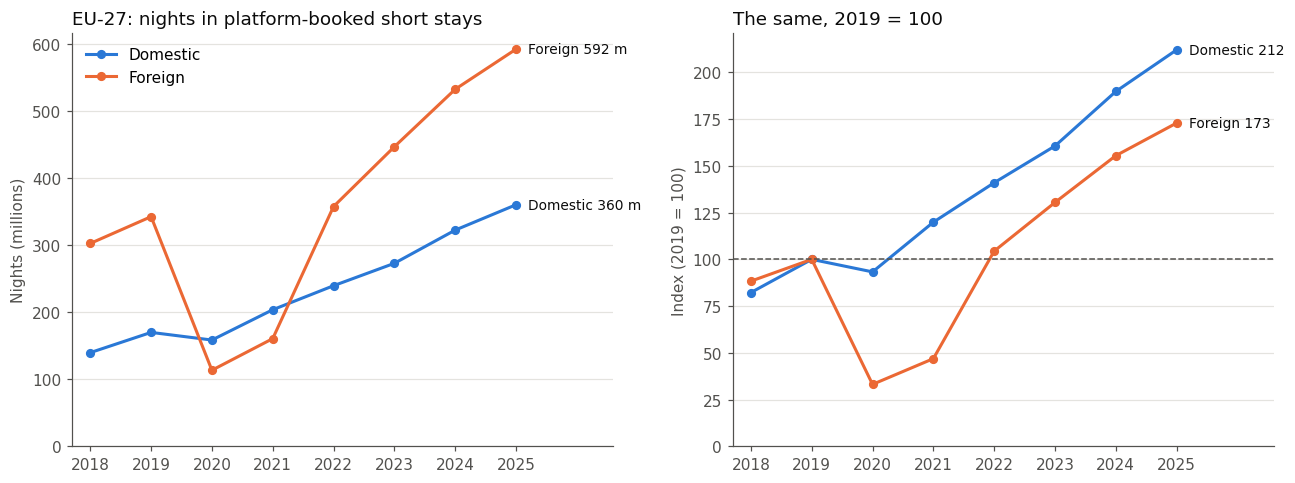

In [2]:
c = df[(df["NUTSLevel"] == 0) & df["Country"].isin(EU27) & (df["Month"] == "Total")]
trend = c.pivot_table(index="Year", columns="ResidenceCountry", values="Value", aggfunc="sum", observed=True) / 1e6
trend["Foreign share %"] = 100 * trend["Foreign"] / trend["Total"]
for r in ["Domestic", "Foreign"]:
    trend[f"{r}, 2019 = 100"] = 100 * trend[r] / trend.loc[2019, r]
print("EU-27, nights in millions:")
display(trend.round(1))
for r in ["Domestic", "Foreign"]:
    print(f"{r}: {trend.loc[2025, r] - trend.loc[2019, r]:+.0f} m nights 2019-2025 ({trend.loc[2025, f'{r}, 2019 = 100'] - 100:+.0f}%)")

# Left: absolute nights; right: the same as an index (2019 = 100), which shows the faster relative growth of domestic stays.
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=110)
for r in ["Domestic", "Foreign"]:
    ax.plot(trend.index, trend[r], color=COLOR[r], lw=2, marker="o", ms=5, label=r)
    ax.annotate(f"{r} {trend[r].iloc[-1]:.0f} m", (trend.index[-1], trend[r].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK)
    col = f"{r}, 2019 = 100"
    ax2.plot(trend.index, trend[col], color=COLOR[r], lw=2, marker="o", ms=5, label=r)
    ax2.annotate(f"{r} {trend[col].iloc[-1]:.0f}", (trend.index[-1], trend[col].iloc[-1]), xytext=(8, 0),
                 textcoords="offset points", va="center", fontsize=9, color=INK)
style(ax, "EU-27: nights in platform-booked short stays", "Nights (millions)")
style(ax2, "The same, 2019 = 100", "Index (2019 = 100)")
for a in (ax, ax2):
    a.set_xticks(trend.index); a.set_xlim(trend.index.min() - 0.3, trend.index.max() + 1.6); a.set_ylim(0, None)
ax2.axhline(100, color=MUTED, lw=1, ls="--")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()

## 1.2 Foreign guests are the majority almost everywhere, and concentrated in a few large regions

* **Countries:** the foreign share ranges from 29% in Germany, 39% in Poland and 40% in France to over 95% in Malta, Iceland and Liechtenstein; the median country is 73% foreign. Since 2019 it fell in 26 of 31 countries — by more than 5 points in 13 (Lithuania, Finland, Estonia, Latvia and Czechia most) — because domestic platform stays grew faster (1.1).
* **Regions:** 78 of 258 NUTS 2 regions are *mainly foreign* (≥ 70%); they have 48% of all nights and 64% of all foreign nights. The 10 regions with the most foreign nights — the Croatian coast, Andalucía, Canarias, Île de France, Cataluña, Valencia, Lazio, Provence, Lombardia, Toscana — hold 36% of them (of 606.8 million foreign nights in all 258 NUTS 2 regions, EU and EFTA; table, last column). Since 2019 the foreign share fell in 74% of regions (median −2.5 points).
* The foreign share and the foreign groups (*Mainly domestic* < 40%, *Mixed*, *Mainly foreign* ≥ 70%) are defined in the indices notebook, A5.

foreign share 2025: median country 73%; fell in 26 of 31 countries since 2019 (by more than 5 points in 13)


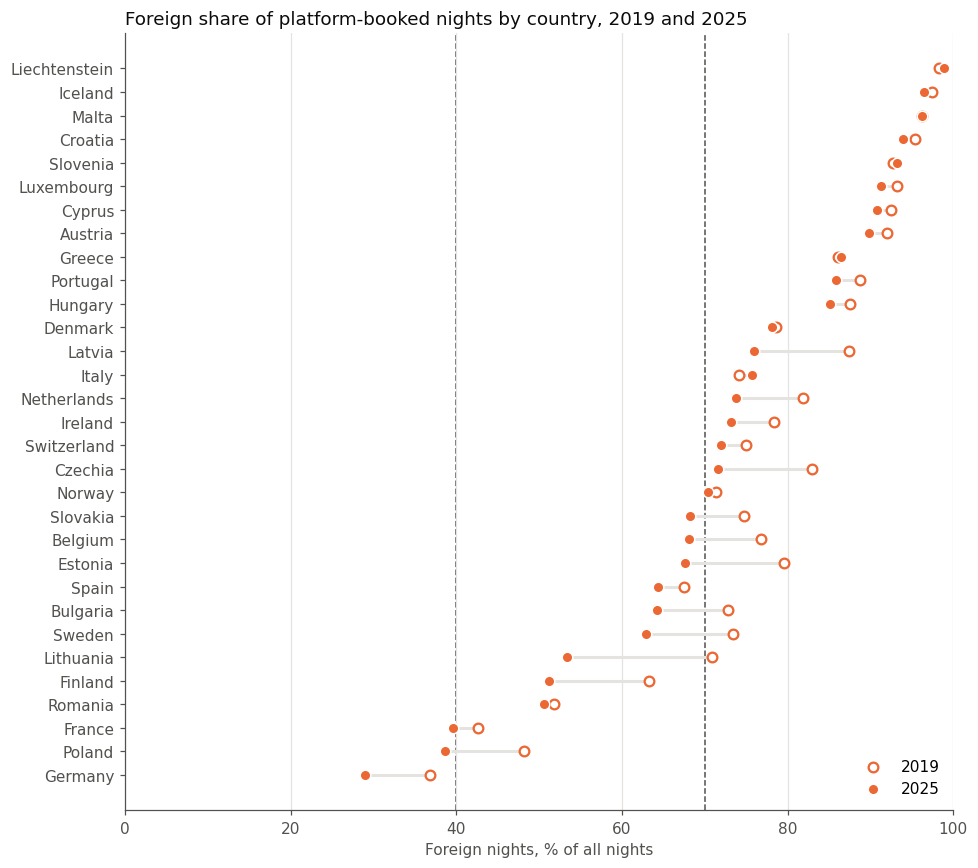

NUTS 2 regions, 2025, by foreign group:


,regions,pct_of_all_nights,pct_of_foreign_nights
ForeignGroup,,,
Mainly domestic,84,23.3,9.7
Mixed,96,28.7,26.1
Mainly foreign,78,48.0,64.2


the 10 regions with most foreign nights hold 36% of the 606.8 million foreign nights in all 258 NUTS 2 regions (EU and EFTA; last column):


,Region,Country,foreign nights (m),% of all foreign nights,running total %,PrcForeign,Gini
0,Jadranska Hrvatska,Croatia,37.64,6.2,6.2,95.31,0.637
1,Andalucía,Spain,31.41,5.2,11.4,62.46,0.214
2,Canarias,Spain,23.55,3.9,15.3,76.50,0.096
3,Ile de France,France,21.67,3.6,18.8,71.86,0.112
4,Cataluña,Spain,21.23,3.5,22.3,78.11,0.254
5,Comunitat Valenciana,Spain,18.29,3.0,25.3,65.19,0.307
6,Lazio,Italy,17.84,2.9,28.3,84.40,0.146
7,Provence-Alpes-Côte d’Azur,France,16.93,2.8,31.1,50.52,0.374
8,Lombardia,Italy,16.00,2.6,33.7,82.81,0.202
9,Toscana,Italy,13.49,2.2,35.9,79.07,0.336


regions with data in 2019 and 2025: 251; foreign share fell in 74% (median change -2.5 points; by more than 5 points in 29%, rose by more than 5 in 5%)


In [3]:
# Countries: foreign share of all nights, 2019 and 2025 (annual rows, all guests).
fs = annual(0).pivot_table(index="Country", columns="Year", values="PrcForeign", observed=True)[[2019, 2025]]
fs["change"] = fs[2025] - fs[2019]
fs = fs.sort_values(2025)
print(f"foreign share 2025: median country {fs[2025].median():.0f}%; "
      f"fell in {(fs['change'] < 0).sum()} of {len(fs)} countries since 2019 (by more than 5 points in {(fs['change'] < -5).sum()})")

# Dumbbell chart: 2019 (hollow) -> 2025 (filled), one row per country.
ax = dumbbell(fs, 2019, 2025,
              [dict(s=40, facecolor="white", edgecolor=COLOR["Foreign"], linewidth=1.5, label="2019", zorder=3),
               dict(s=48, color=COLOR["Foreign"], edgecolor="white", linewidth=1, label="2025", zorder=4)],
              (0, 100), "Foreign nights, % of all nights", "Foreign share of platform-booked nights by country, 2019 and 2025")
for xv in (40, 70):
    ax.axvline(xv, color=MUTED, lw=1, ls="--", zorder=0)
plt.tight_layout(); plt.show()

# Regions, 2025: how many regions - and how many nights - in each foreign group.
reg_f = ann.dropna(subset=["PrcForeign"])
fo_n = annual(2, 2025, "Foreign").set_index("NUTSCode")["Value"]          # foreign nights per region
reg_f = reg_f.assign(foreign_nights=reg_f["NUTSCode"].map(fo_n))
print("NUTS 2 regions, 2025, by foreign group:")
display(reg_f.groupby("ForeignGroup", observed=True).agg(
    regions=("Region", "size"),
    pct_of_all_nights=("Value", lambda s: round(100 * s.sum() / reg_f["Value"].sum(), 1)),
    pct_of_foreign_nights=("foreign_nights", lambda s: round(100 * s.sum() / reg_f["foreign_nights"].sum(), 1))))

# Where are the foreign nights? The 10 regions with most foreign nights and their share of the EU-wide total.
tot_f = reg_f["foreign_nights"].sum()                                  # all foreign nights in NUTS 2 regions (EU + EFTA)
top10 = reg_f.nlargest(10, "foreign_nights")
top10 = top10.assign(**{"foreign nights (m)": top10["foreign_nights"] / 1e6,
                        "% of all foreign nights": 100 * top10["foreign_nights"] / tot_f})
top10["running total %"] = top10["% of all foreign nights"].cumsum()
print(f"the 10 regions with most foreign nights hold {top10['running total %'].iloc[-1]:.0f}% of the {tot_f / 1e6:.1f} million "
      f"foreign nights in all {len(reg_f)} NUTS 2 regions (EU and EFTA; last column):")
display(top10[["Region", "Country", "foreign nights (m)", "% of all foreign nights", "running total %", "PrcForeign", "Gini"]]
        .round({"foreign nights (m)": 2, "% of all foreign nights": 1, "running total %": 1, "Gini": 3}).reset_index(drop=True))

# Change since 2019, regions with data in both years.
r19 = annual(2, 2019).set_index("NUTSCode")["PrcForeign"]
d_ = (reg_f.set_index("NUTSCode")["PrcForeign"] - r19).dropna()
print(f"regions with data in 2019 and 2025: {len(d_)}; foreign share fell in {(d_ < 0).mean():.0%} "
      f"(median change {d_.median():+.1f} points; by more than 5 points in {(d_ < -5).mean():.0%}, rose by more than 5 in {(d_ > 5).mean():.0%})")

# 2. Seasonal patterns

## 2.1 Most regions have a single summer season centred on July–August; since 2023 the year has been somewhat less concentrated in it

* **One summer season.** Of the 258 NUTS 2 regions, 199 have one season (all guests, 2025); 152 of them are centred on July and 42 on August. July is the *centre* of the season, not always its busiest month. Foreign guests' nights are spread evenly over July and August (16.5% and 16.6% of their year), and a larger share of them falls in June and September than of domestic guests' nights (10.9% vs 9.1% and 10.0% vs 7.7%). Domestic guests concentrate more in August (18.9%) and in December (chart and table).
* **Less concentrated since 2023.** The EU-27 Gini index was 0.295 in 2019 and 0.298 in 2022, dropped to 0.264 in 2023 and has stayed there (0.262 in 2024, 0.261 in 2025) — for both guest groups. It spiked in 2020–21, when travel shrank to the summer. Part of the drop may reflect wider use of the platforms, not only a change in when people travel.
* **The fall comes from the countries themselves becoming less seasonal.** A change in the mix could have produced it too, since nights grew unevenly: France (+2.9 points) and Greece gained share of EU nights, Portugal, Spain and Croatia lost it. But these shifts cancel out — gains and losses are unrelated to how seasonal a country was (correlation 0.02). With the 2025 country shares and the 2019 monthly patterns, the EU Gini would be 0.296: no fall. With the 2019 shares and the 2025 patterns it is 0.261: the full fall (last two tables). Whether the change is within regions or between regions of the same country is not tested here.

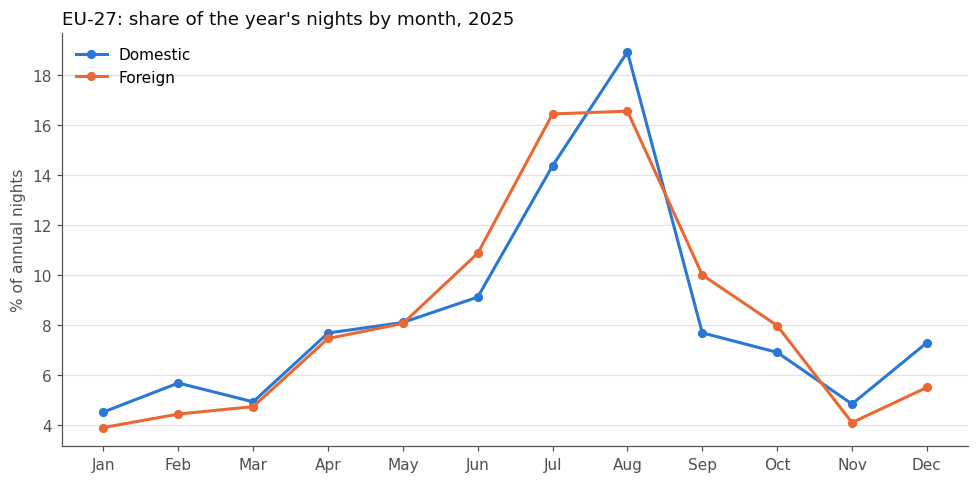

EU-27, 2025: % of each guest group's annual nights falling in each month (the chart):


Month,January,February,March,April,May,June,July,August,September,October,November,December
ResidenceCountry,,,,,,,,,,,,
Domestic,4.5,5.7,4.9,7.7,8.1,9.1,14.4,18.9,7.7,6.9,4.8,7.3
Foreign,3.9,4.4,4.7,7.5,8.1,10.9,16.5,16.6,10.0,8.0,4.1,5.5


Season centre month of one-season NUTS 2 regions, 2025:


,Domestic,Foreign,Total
SeasonCentreMonth,,,
January,0,2,1
February,5,3,2
March,1,1,0
June,2,1,0
July,115,166,152
August,52,41,42
September,5,1,0
October,0,1,1
November,0,0,1


Gini index of EU-27 nights by year:


,2018,2019,2020,2021,2022,2023,2024,2025
Domestic,0.279,0.283,0.467,0.384,0.266,0.247,0.241,0.241
Foreign,0.306,0.302,0.460,0.478,0.323,0.280,0.277,0.275
Total,0.296,0.295,0.450,0.421,0.298,0.264,0.262,0.261


Countries' share of EU-27 nights, the five largest losers and gainers 2019-2025:


,% of EU nights 2019,% of EU nights 2025,change (points),Gini 2019
Country,,,,
Portugal,6.068,5.202,-0.866,0.312
Spain,20.628,19.913,-0.715,0.255
Croatia,5.007,4.408,-0.599,0.644
Netherlands,1.835,1.250,-0.585,0.219
Czechia,1.836,1.277,-0.559,0.154
Sweden,0.713,0.964,0.251,0.357
Romania,0.819,1.090,0.271,0.264
Greece,4.747,5.480,0.733,0.495
Poland,3.845,4.665,0.819,0.233


correlation of the share change with the country's 2019 Gini: 0.02 (gains and losses do not favour less seasonal countries)
EU-27 Gini with the countries' monthly patterns and their shares of EU nights taken from different years:


,2019 (actual),"2019 monthly patterns, 2025 country shares (only the mix changes)","2025 monthly patterns, 2019 country shares (only the patterns change)",2025 (actual)
Domestic,0.283,0.280,0.243,0.241
Foreign,0.302,0.308,0.270,0.275
Total,0.295,0.296,0.261,0.261


In [4]:
prof = (df[(df["NUTSLevel"] == 0) & df["Country"].isin(EU27) & (df["Year"] == 2025) & (df["Month"] != "Total")]
        .pivot_table(index="Month", columns="ResidenceCountry", values="Value", aggfunc="sum", observed=True))
prof = 100 * prof / prof.sum()
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=110)
for r in ["Domestic", "Foreign"]:
    ax.plot(np.arange(12), prof[r], color=COLOR[r], lw=2, marker="o", ms=5, label=r)
ax.set_xticks(np.arange(12), [m[:3] for m in MONTH_NAMES])
style(ax, "EU-27: share of the year's nights by month, 2025", "% of annual nights")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()
print("EU-27, 2025: % of each guest group's annual nights falling in each month (the chart):")
display(prof[["Domestic", "Foreign"]].T.round(1))

print("Season centre month of one-season NUTS 2 regions, 2025:")
cm = pd.concat([annual(2, 2025, r).query("SeasonShape == 'One season'")["SeasonCentreMonth"].value_counts().rename(r)
                for r in ["Domestic", "Foreign", "Total"]], axis=1)
display(cm.reindex([m for m in MONTH_NAMES if m in cm.index]).fillna(0).astype(int))

eu = df[(df["NUTSLevel"] == 0) & df["Country"].isin(EU27) & (df["Month"] != "Total")]
def eu_months(year, res):
    """EU-27 nights by month (sum of the country rows) for one year and guest group."""
    return (eu[(eu["Year"] == year) & (eu["ResidenceCountry"] == res)].groupby("Month", observed=True)["Value"].sum()
            .reindex(MONTH_NAMES).to_numpy(float))
eu_g = {r: {y: round(gini(eu_months(y, r)), 3) for y in range(2018, 2026)} for r in ["Domestic", "Foreign", "Total"]}
print("Gini index of EU-27 nights by year:")
display(pd.DataFrame(eu_g).T)

# Why did the EU Gini fall? (a) the countries' own monthly patterns flattened, or (b) the mix changed: nights moved
# towards less seasonal countries. (b) is possible because nights grew unevenly - first, how the mix changed:
sh = eu[eu["ResidenceCountry"] == "Total"].groupby(["Year", "Country"], observed=True)["Value"].sum().unstack("Year")[[2019, 2025]]
sh = 100 * sh / sh.sum()
mix_shift = pd.DataFrame({"% of EU nights 2019": sh[2019], "% of EU nights 2025": sh[2025], "change (points)": sh[2025] - sh[2019],
                          "Gini 2019": annual(0, 2019).set_index("Country")["Gini"].reindex(sh.index)}).sort_values("change (points)")
print("Countries' share of EU-27 nights, the five largest losers and gainers 2019-2025:")
display(pd.concat([mix_shift.head(5), mix_shift.tail(5)]).round(3))
mix_corr = np.corrcoef(mix_shift["change (points)"], mix_shift["Gini 2019"])[0, 1]
print(f"correlation of the share change with the country's 2019 Gini: {mix_corr:.2f} (gains and losses do not favour less seasonal countries)")

# Then recombine country patterns and country shares from different years.
def eu_gini(res, prof_year, weight_year):
    m = eu[eu["ResidenceCountry"] == res].pivot_table(index=["Year", "Country"], columns="Month", values="Value",
                                                       observed=True).reindex(columns=MONTH_NAMES)
    P = m.loc[prof_year]; P = P.div(P.sum(axis=1), axis=0)     # each country's monthly shares
    w = m.loc[weight_year].sum(axis=1); w = w / w.sum()        # each country's share of EU nights
    return round(gini(P.mul(w, axis=0).sum().to_numpy()), 3)
mix = pd.DataFrame({r: {"2019 (actual)": eu_gini(r, 2019, 2019),
                        "2019 monthly patterns, 2025 country shares (only the mix changes)": eu_gini(r, 2019, 2025),
                        "2025 monthly patterns, 2019 country shares (only the patterns change)": eu_gini(r, 2025, 2019),
                        "2025 (actual)": eu_gini(r, 2025, 2025)} for r in ["Domestic", "Foreign", "Total"]}).T
print("EU-27 Gini with the countries' monthly patterns and their shares of EU nights taken from different years:")
display(mix)

## 2.2 Five season patterns

Each region gets one of five patterns from its monthly profile (indices notebook, A7): **Strong summer season** (July–August at least 2.5 × an average month; 49 regions — the Croatian coast, Provence, the French Atlantic), **Summer season** (1.5–2.5 ×; 119 regions — most of Spain and Italy), **Summer season + winter shoulder** (7 regions — Małopolskie, Dolnośląskie, Bolzano, Trento), **Winter-based seasons** (19 regions — the ski regions: Rhône-Alpes, Tirol, Salzburg) and **Mild or no season** (64 regions — Canarias and the capitals). By shape: 199 regions have one season, 15 two (winter and summer), 44 no clear season.

The two small groups are the least firm. **Summer season + winter shoulder** (7 regions) is not a real group: only 43% of its regions keep the pattern through 2023–25, its profiles fit it no better than the neighbouring groups, and moving its winter cut-off from 1.0 to 1.1 changes 4 of the 7. **Winter-based seasons** (19 regions) is reasonably firm (79% keep it through 2023–25), but a few regions near the one/two-season border — Tirol, Kärnten, Innlandet and the Norrland regions — switch in and out between years (2.4; robustness in the indices notebook, R3–R4).

SeasonPattern,Strong summer season,Summer season,Summer season + winter shoulder,Winter-based seasons,Mild or no season
"NUTS 2 regions, 2025",49,119,7,19,64


SeasonShape,One season,No clear season,Two seasons
"NUTS 2 regions, 2025",199,44,15


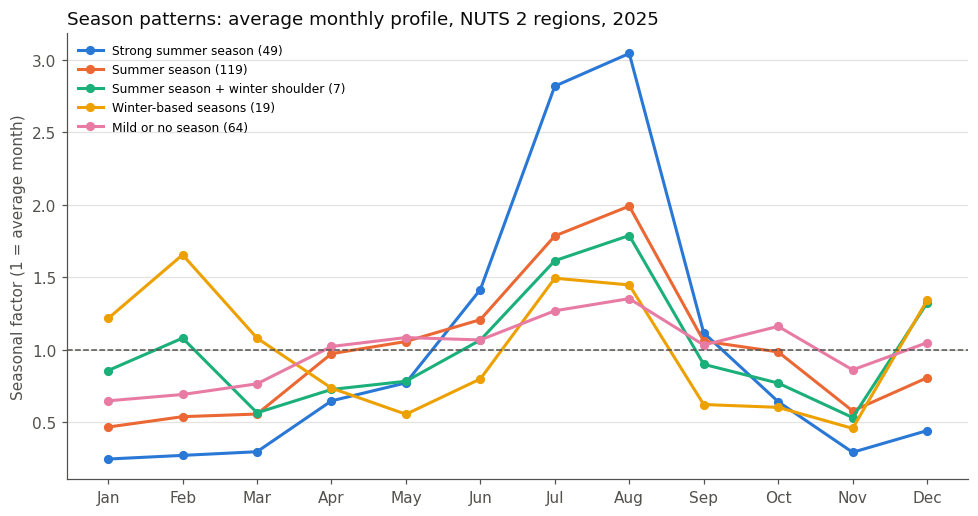

Largest regions per pattern:


,SeasonPattern,Region,Country,Gini,SeasonShape
0,Strong summer season,Jadranska Hrvatska,Croatia,0.6370,One season
1,Strong summer season,Provence-Alpes-Côte d’Azur,France,0.3735,One season
2,Strong summer season,Languedoc-Roussillon,France,0.4051,One season
3,Strong summer season,Aquitaine,France,0.4358,One season
4,Summer season,Andalucía,Spain,0.2139,One season
5,Summer season,Comunitat Valenciana,Spain,0.3067,One season
6,Summer season,Cataluña,Spain,0.2537,One season
7,Summer season,Lombardia,Italy,0.2022,One season
8,Summer season + winter shoulder,Małopolskie,Poland,0.1717,One season
9,Summer season + winter shoulder,Dolnośląskie,Poland,0.1708,One season


In [5]:
# Seasonal factors (month / average month) of every reliable series; average profile of each pattern, NUTS 2, 2025, all guests.
fac = wide[volume_ok].div(wide[volume_ok].sum(axis=1), axis=0) * T
p25 = ok.set_index(KEY_SERIES)["SeasonPattern"]
display(p25.value_counts().reindex(PATTERNS).rename("NUTS 2 regions, 2025").to_frame().T)
display(ok["SeasonShape"].value_counts().rename("NUTS 2 regions, 2025").to_frame().T)

fig, ax = plt.subplots(figsize=(9, 4.8), dpi=110)
for p in PATTERNS:
    rows_ = fac.loc[p25[p25 == p].index]
    if len(rows_):
        ax.plot(np.arange(12), rows_.mean().values, color=PATTERN_COLOR[p], lw=2, marker="o", ms=5, label=f"{p} ({len(rows_)})")
ax.axhline(1, color=MUTED, lw=1, ls="--")
ax.set_xticks(np.arange(12), [m[:3] for m in MONTH_NAMES])
style(ax, "Season patterns: average monthly profile, NUTS 2 regions, 2025", "Seasonal factor (1 = average month)")
ax.legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()
print("Largest regions per pattern:")
display(ok.sort_values("Value", ascending=False).groupby("SeasonPattern", observed=True).head(4)
        .sort_values(["SeasonPattern", "Value"], ascending=[True, False])[["SeasonPattern", "Region", "Country", "Gini", "SeasonShape"]]
        .reset_index(drop=True))

## 2.3 Countries: Croatia, Greece and Slovenia are the most seasonal; Spain is the least seasonal of the big sun destinations

* Chart: 2019 (hollow) and 2025 (filled) for each country.
* Seasonality is not only Mediterranean: Sweden and Denmark have been more seasonal than Italy, France and Spain since 2023; Ireland has been above Italy since 2024, and by a margin within normal year-to-year movement (0.304 vs 0.291 in 2025).
* A country's Gini averages over its regions (Spain combines winter-peaking Canarias with summer coasts and year-round cities), so countries look less seasonal than many of their regions.
* Country changes 2019–2025 are mixed: Gini fell in 18 of 31 countries, but only 15 falls and 5 rises are larger than the country's normal year-to-year movement (its largest annual change 2022–2025). The biggest falls: Bulgaria, Romania, Cyprus, Malta, Spain and Italy.

,nights (m),PrcForeign,Gini,Gini domestic,Gini foreign,SeasonShape,centre,pattern,foreign effect
Country,,,,,,,,,
Croatia,41.944,93.98,0.612,0.343,0.629,One season,July,Strong summer season,Sharpening
Greece,52.149,86.47,0.464,0.279,0.497,One season,July,Strong summer season,Sharpening
Slovenia,4.529,93.24,0.427,0.164,0.450,One season,July,Strong summer season,Sharpening
Sweden,9.169,62.85,0.356,0.351,0.370,One season,July,Strong summer season,Small or unclear
Denmark,8.215,78.16,0.344,0.269,0.369,One season,July,Summer season,Sharpening
Ireland,8.419,73.15,0.304,0.252,0.325,One season,July,Summer season,Sharpening
Latvia,2.045,75.97,0.299,0.195,0.333,One season,July,Summer season,Sharpening
Italy,138.737,75.70,0.291,0.289,0.299,One season,July,Summer season,Small or unclear
Estonia,1.914,67.65,0.290,0.207,0.331,One season,July,Summer season,Sharpening


Gini fell in 18 of 31 countries; 9 changed by less than 0.01
larger than normal annual movement: 15 falls, 5 rises


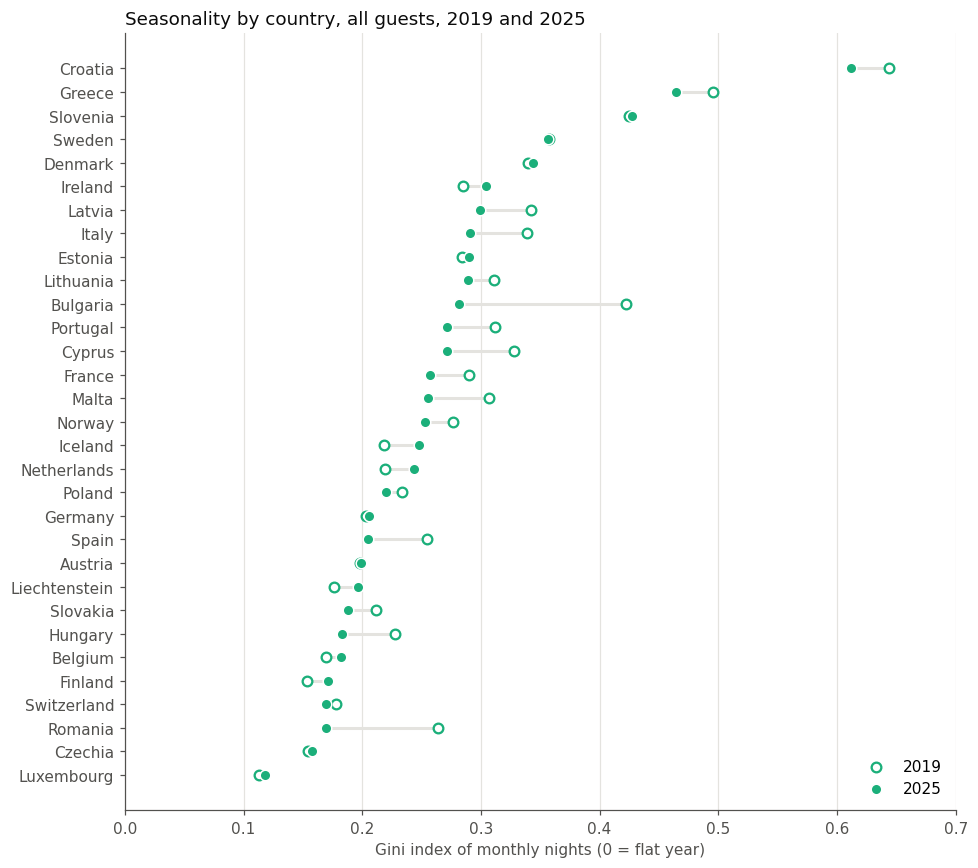

In [6]:
dom, fo = annual(0, 2025, "Domestic").set_index("Country"), annual(0, 2025, "Foreign").set_index("Country")
ct = cty.set_index("Country")
by_cty = pd.DataFrame({"nights (m)": ct["Value"] / 1e6, "PrcForeign": ct["PrcForeign"], "Gini": ct["Gini"],
                       "Gini domestic": dom["Gini"], "Gini foreign": fo["Gini"], "SeasonShape": ct["SeasonShape"],
                       "centre": ct["SeasonCentreMonth"], "pattern": ct["SeasonPattern"],
                       "foreign effect": ct["ForeignSeasonEffect"]}).sort_values("Gini", ascending=False)
display(by_cty.round(3))

g_c = annual(0).pivot_table(index="Country", columns="Year", values="Gini", observed=True)
g_c["change 2019-2025"] = g_c[2025] - g_c[2019]
ch = g_c["change 2019-2025"].dropna()
print(f"Gini fell in {(ch < 0).sum()} of {len(ch)} countries; {(ch.abs() < 0.01).sum()} changed by less than 0.01")
# Compare each change with the country's normal movement: its largest change between consecutive years 2022-2025.
normal = pd.concat([(g_c[y] - g_c[y - 1]).abs() for y in (2023, 2024, 2025)], axis=1).max(axis=1).reindex(ch.index)
print(f"larger than normal annual movement: {((ch < 0) & (ch.abs() > normal)).sum()} falls, {((ch > 0) & (ch.abs() > normal)).sum()} rises")

# Chart: Gini index by country, 2019 (hollow) and 2025 (filled).
gd = g_c[[2019, 2025]].dropna().sort_values(2025)
dumbbell(gd, 2019, 2025,
         [dict(s=40, facecolor="white", edgecolor=COLOR["Total"], linewidth=1.5, label="2019", zorder=3),
          dict(s=48, color=COLOR["Total"], edgecolor="white", linewidth=1, label="2025", zorder=4)],
         (0, 0.7), "Gini index of monthly nights (0 = flat year)", "Seasonality by country, all guests, 2019 and 2025")
plt.tight_layout(); plt.show()

## 2.4 Two-season regions: Gini overstates the seasonality of the Alps

Gini and S_R agree for almost all regions; they part only for regions with two separate seasons — nearly all Alpine or Nordic/Central European ski-and-summer regions — which S_R (using the calendar order) rates as clearly less seasonal.

On the Gini map, Salzburg (0.31), Valle d'Aosta (0.32), Innlandet, Norra Mellansverige and Mellersta Norrland fall in the *High* class and Tirol (0.29) just below it — next to one-summer beach regions.

A few regions sit near the one/two-season border (PCD ÷ S_R between 0.7 and 0.9) and switch between years — Tirol, Kärnten, Innlandet and the Norrland regions (table at the end). Salzburg and Rhône-Alpes are clear two-season cases in every year except 2021, when the ski season was closed.

correlations:


,Season75,Gini,SR
Season75,1.00,-0.96,-0.93
Gini,-0.96,1.00,0.97
SR,-0.93,0.97,1.00


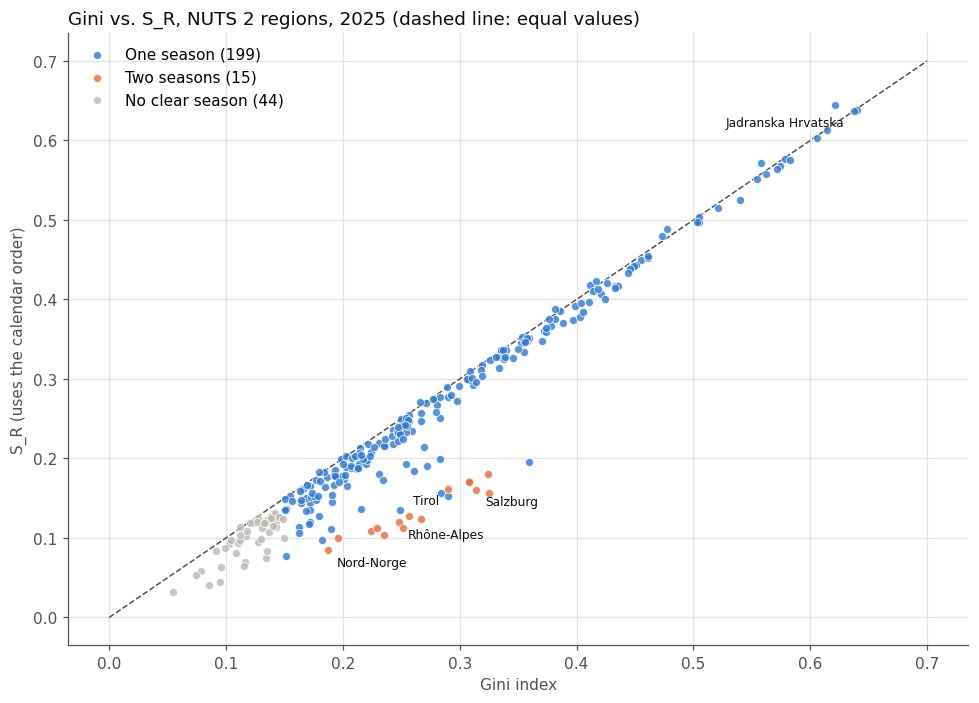

Two-season regions and their class on the Gini map:


,Region,Country,Value,PrcForeign,Gini,GiniMapGroup,SR,InlandMountainGroup
0,Rhône-Alpes,France,24808523,38.18,0.2478,Medium,0.1196,Predominantly inland mountain
1,Tirol,Austria,6574355,96.73,0.2900,Medium,0.1614,Predominantly inland mountain
2,Salzburg,Austria,4778276,93.54,0.3142,High,0.1602,Predominantly inland mountain
3,Région lémanique,Switzerland,3470879,67.07,0.2243,Medium,0.1092,Predominantly inland mountain
4,Steiermark,Austria,2267284,75.92,0.2515,Medium,0.1129,Predominantly inland mountain
5,Nord-Norge,Norway,2139743,86.27,0.1871,Low,0.0844,Non-inland mountain
6,Severovýchod,Czechia,1646971,53.51,0.2349,Medium,0.1031,Partly inland mountain
7,Ostschweiz,Switzerland,1549297,55.51,0.2294,Medium,0.1125,Predominantly inland mountain
8,Stredné Slovensko,Slovakia,1528393,63.64,0.2670,Medium,0.1238,Predominantly inland mountain
9,Vorarlberg,Austria,1161709,93.82,0.2564,Medium,0.1278,Predominantly inland mountain


Near the one/two-season border - PCD / S_R by year (below 0.8 = two seasons):


,2023,2024,2025
Region,,,
Yugozapaden,0.82,0.79,0.61
Yuzhen tsentralen,1.07,0.95,0.80
Arnsberg,0.89,1.02,0.95
Provincia Autonoma di Trento,1.01,0.88,1.01
Kärnten,0.75,0.80,0.86
Tirol,0.78,0.85,0.72
Norra Mellansverige,0.98,0.72,0.68
Mellersta Norrland,0.62,0.78,0.71
Övre Norrland,0.87,0.67,0.74


In [7]:
w7 = wide.loc[[k for k in ok.set_index(KEY_SERIES).index if k in wide.index]]
ok7 = ok.join(pd.Series([round(s_r(r), 4) for r in w7.to_numpy()], index=w7.index, name="SR"), on=KEY_SERIES)
print("correlations:"); display(ok7[["Season75", "Gini", "SR"]].astype(float).corr().round(2))
SHAPE_COLOR = {"One season": "#2a78d6", "Two seasons": "#eb6834", "No clear season": "#b8b7b2"}
fig, ax = plt.subplots(figsize=(9, 6.5), dpi=110)
for shp, col in SHAPE_COLOR.items():
    g_ = ok7[ok7["SeasonShape"] == shp]
    ax.scatter(g_["Gini"], g_["SR"], s=28, color=col, alpha=0.8, edgecolor="white", linewidth=0.6, label=f"{shp} ({len(g_)})", zorder=3)
ax.plot([0, 0.7], [0, 0.7], color=MUTED, lw=1, ls="--", zorder=1)
for name, dx_, ha in [("Rhône-Alpes", 6, "left"), ("Tirol", -6, "right"), ("Salzburg", 6, "left"),
                      ("Nord-Norge", 6, "left"), ("Jadranska Hrvatska", -6, "right")]:
    r = ok7[ok7["Region"] == name]
    if len(r):
        ax.annotate(name, (r["Gini"].iloc[0], r["SR"].iloc[0]), xytext=(dx_, -10), textcoords="offset points", ha=ha, fontsize=8, color=INK)
style(ax, "Gini vs. S_R, NUTS 2 regions, 2025 (dashed line: equal values)", "S_R (uses the calendar order)")
ax.set_xlabel("Gini index", color=MUTED); ax.grid(axis="x", color=GRIDC, lw=0.8)
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()
print("Two-season regions and their class on the Gini map:")
display(ok7[ok7["SeasonShape"] == "Two seasons"][["Region", "Country", "Value", "PrcForeign", "Gini", "GiniMapGroup", "SR", "InlandMountainGroup"]].sort_values(
    "Value", ascending=False).reset_index(drop=True))

# Regions near the one/two-season border (PCD / S_R between 0.7 and 0.9 in any of 2023-2025), all guests.
near = []
for code_ in ok["NUTSCode"]:
    r_ = {}
    for y in (2023, 2024, 2025):
        k = (code_, y, "Total")
        if k in wide.index and wide.loc[k].notna().all():
            v = wide.loc[k].to_numpy(float); r_[y] = round(pcd_centre(v)[0] / s_r(v), 2)
    if any(0.7 <= x <= 0.9 for x in r_.values()):
        near.append({"Region": regions.at[code_, "Region"], **r_})
print("Near the one/two-season border - PCD / S_R by year (below 0.8 = two seasons):")
pd.DataFrame(near).set_index("Region")

# 3. Do foreign guests influence seasonality?

Four different questions, answered in turn:

* **3.1** Are regions that depend on foreign guests more seasonal? — *Not in general.*
* **3.2** Are foreign guests themselves more seasonal than domestic guests? — *Yes, in about three-quarters of regions.*
* **3.3** How much does their timing add to a region's seasonality? — *Little in the typical region, a lot where they dominate.*
* **3.4** Where do they lower it? — *Where domestic guests make a sharp August peak.*

The main measure is **ForeignTimingEffect** (indices notebook, A6b): the region's Gini index minus the Gini if foreign guests kept their number of nights but travelled in the same months as domestic guests. It is an accounting comparison, not a causal effect. The marginal-effect measure of the literature, RMEForeign, agrees with it (rank correlation 0.80) and is reported in Appendix A.

## 3.1 Foreign dependency is not the same as seasonality

**Foreign share does not tell you how seasonal a region is.** Mainly-foreign regions include both the most seasonal places (the Croatian coast, the Greek islands) and the least seasonal (Paris, Madrid, Canarias).

* **Across regions** the link is weak: rank correlation 0.14. Because regions of the same country are not independent, its 95% interval is computed by resampling whole countries: −0.10 to 0.30, which includes zero.
* **Across countries** it is also weak: 0.19, not significant (p = 0.31).
* **Within countries** it is slightly negative (−0.19, more than chance: p < 0.01): a country's more foreign regions tend to be its less seasonal ones — mostly capitals and cities. This is strongest in Belgium, Romania, Denmark, Portugal, Germany and Italy; Greece and the Netherlands go the other way (table below).
* **Why:** the within-country pattern disappears once geography is taken into account (4.2) — it reflects cities attracting foreign guests, not something about foreign guests themselves.

The scatter plots each region by foreign share and Gini index — the two dimensions of the planned map.

**Double exposure** — the map's top-right class, *Mainly foreign* (≥ 70%) × *High* Gini (≥ 0.30): about 30 regions with about a fifth of all nights — the Croatian coast, Greek islands, Balearics, Algarve, Sicilia, Toscana, Veneto. They depend on foreign guests *and* on a short season. The size of this class depends on its cut-offs: with the Gini cut 0.02 lower or higher and the foreign cut 5 points lower or higher, it holds 16–45 regions and 13–27% of nights (table below).

**Regions vs nights on the map.** A map shows how many regions — and how much area — fall in each of the nine classes, not how many nights: *Mixed × High* has the most regions (40), while *Mainly foreign × High* holds the most nights (19.7%; last tables).

rank correlation PrcForeign ~ Gini: NUTS 2 regions 0.14 | countries 0.19 (p = 0.31)
95% interval, resampling countries: [-0.1  0.3]
within-country rank correlation (248 regions in countries with 3+ regions): -0.19
  shuffling Gini within countries: p = 0.0035 (two-sided)
Rank correlation foreign share ~ Gini inside each country (5+ regions):


c_,Belgium,Romania,Denmark,Portugal,Germany,Italy,Norway,Switzerland,Czechia,Sweden,Hungary,Poland,Finland,France,Spain,Austria,Bulgaria,Netherlands,Greece
regions,11.00,8.00,5.0,9.00,38.00,21.00,6.00,7.00,8.00,8.00,8.00,17.0,5.0,27.00,19.00,9.0,6.00,12.00,13.00
rank correlation,-0.95,-0.81,-0.8,-0.65,-0.55,-0.44,-0.43,-0.25,-0.24,-0.21,-0.14,-0.1,-0.1,0.01,0.09,0.1,0.14,0.46,0.75


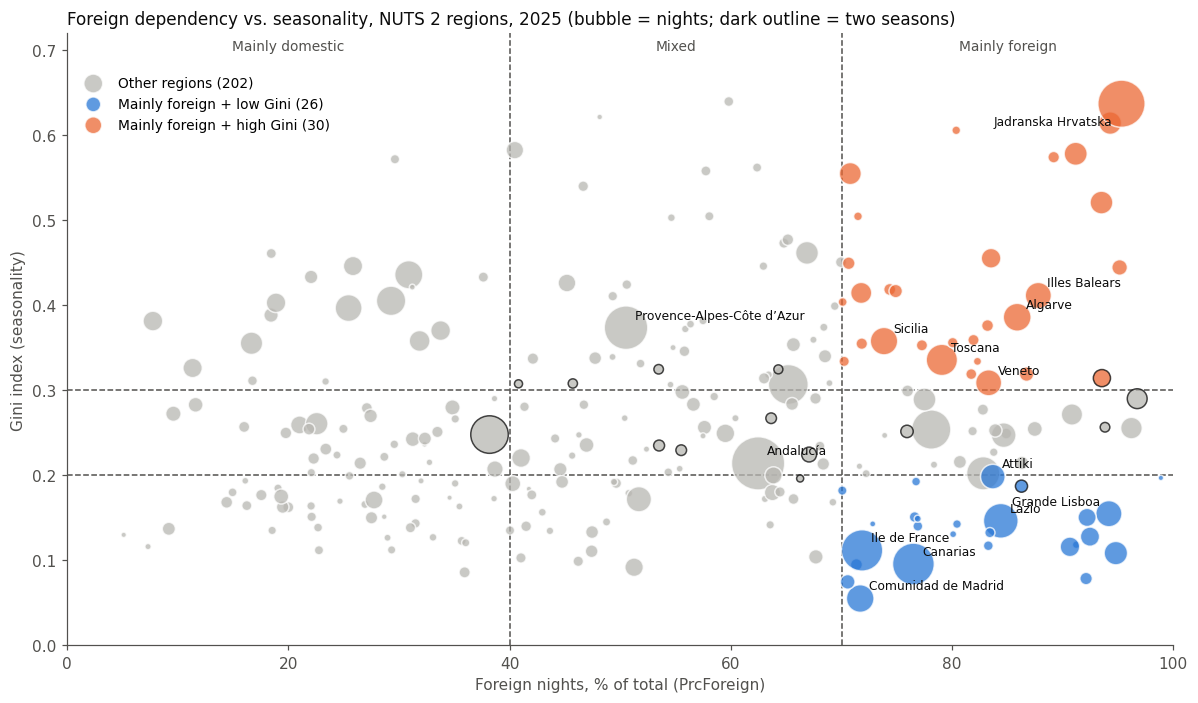

Double exposure (mainly foreign AND high Gini): 30 regions, 19.7% of all nights


,Region,Country,Value,PrcForeign,Gini,SeasonShape
0,Jadranska Hrvatska,Croatia,39491950,95.31,0.6370,One season
1,Toscana,Italy,17058461,79.07,0.3356,One season
2,Algarve,Portugal,13370699,85.88,0.3858,One season
3,Sicilia,Italy,13024839,73.84,0.3577,One season
4,Illes Balears,Spain,11769481,87.79,0.4114,One season
5,Veneto,Italy,11640760,83.30,0.3087,One season
6,Notio Aigaio,Greece,9037378,91.17,0.5781,One season
7,Kriti,Greece,8828327,93.50,0.5207,One season
8,Ionia Nisia,Greece,8644420,94.29,0.6142,One season
9,Sardegna,Italy,8248040,70.79,0.5548,One season


Double exposure under other cut-offs:


regions             % of nights            
foreign cut %      65    70    75          65    70    75
Gini cut                                                 
0.28             45.0  33.0  23.0        26.9  21.5  17.2
0.30             40.0  30.0  20.0        24.6  19.7  15.4
0.32             34.0  26.0  16.0        19.5  17.5  13.2

Countries: foreign share vs Gini


,PrcForeign,Gini
Country,,
Croatia,93.98,0.612
Malta,96.21,0.255
Austria,89.84,0.199
Greece,86.47,0.464
Germany,28.97,0.205
Spain,64.39,0.205


Share of all nights per class (%):


GiniMapGroup,Low,Medium,High
ForeignGroup,,,
Mainly domestic,4.4,8.7,10.3
Mixed,5.8,10.6,12.3
Mainly foreign,16.9,11.5,19.7


Largest regions per class:


,BivariateCode,ForeignGroup,GiniMapGroup,Region,Country,PrcForeign,Gini,SeasonShape
0,11.0,Mainly domestic,Low,La Réunion,France,9.19,0.1369,No clear season
1,11.0,Mainly domestic,Low,Castilla y León,Spain,19.35,0.1749,One season
2,11.0,Mainly domestic,Low,Dolnośląskie,Poland,27.74,0.1708,One season
3,12.0,Mainly domestic,Medium,Centre — Val de Loire,France,21.01,0.2591,One season
4,12.0,Mainly domestic,Medium,Midi-Pyrénées,France,22.56,0.2606,One season
5,12.0,Mainly domestic,Medium,Rhône-Alpes,France,38.18,0.2478,Two seasons
6,13.0,Mainly domestic,High,Bretagne,France,25.44,0.3966,One season
7,13.0,Mainly domestic,High,Languedoc-Roussillon,France,29.28,0.4051,One season
8,13.0,Mainly domestic,High,Aquitaine,France,30.88,0.4358,One season
9,21.0,Mixed,Low,Warszawski stołeczny,Poland,51.25,0.0917,No clear season


In [8]:
rho_c, p_c = stats.spearmanr(cty["PrcForeign"], cty["Gini"], nan_policy="omit")
print("rank correlation PrcForeign ~ Gini: NUTS 2 regions", round(ok["PrcForeign"].rank().corr(ok["Gini"].rank()), 2),
      f"| countries {rho_c:.2f} (p = {p_c:.2f})")
# Regions of one country are not independent: resample whole countries (bootstrap) for an honest 95% interval.
rng = np.random.default_rng(0)
oc = ok["Country"].astype(str)
rk = lambda d: d["PrcForeign"].rank().corr(d["Gini"].rank())
pos_c = {c_: np.flatnonzero(oc == c_) for c_ in oc.unique()}         # row positions of each country
boot = [rk(ok.iloc[np.concatenate([pos_c[c_] for c_ in rng.choice(oc.unique(), oc.nunique())])]) for _ in range(1000)]
boot_ci = np.percentile(boot, [2.5, 97.5])
print("95% interval, resampling countries:", boot_ci.round(2))
# Within countries: correlation of ranks after removing each country's average rank (countries with 3+ regions).
w_ = ok.assign(rF=ok["PrcForeign"].rank(), rG=ok["Gini"].rank(), c_=oc).groupby("c_").filter(lambda d: len(d) >= 3)
dm_ = w_[["rF", "rG"]] - w_.groupby("c_")[["rF", "rG"]].transform("mean")
obs_w = dm_["rF"].corr(dm_["rG"])
print(f"within-country rank correlation ({len(w_)} regions in countries with 3+ regions): {obs_w:.2f}")
# Is it more than chance? Shuffle the Gini ranks within each country and recompute (2,000 times).
# Shuffling inside a country keeps its mean, so the country-demeaned ranks can be shuffled directly.
rF_dm, rG_dm = dm_["rF"].to_numpy(), dm_["rG"].to_numpy()
pos_w = [np.flatnonzero(w_["c_"] == c_) for c_ in sorted(w_["c_"].unique())]
def shuffled_corr():
    g = rG_dm.copy()
    for ix in pos_w:
        g[ix] = rng.permutation(g[ix])
    return np.corrcoef(rF_dm, g)[0, 1]
perm_w = np.array([shuffled_corr() for _ in range(2000)])
print(f"  shuffling Gini within countries: p = {(np.abs(perm_w) >= abs(obs_w)).mean():.4f} (two-sided)")
# The reversal is not the same everywhere: rank correlation inside each country with 5+ regions.
per_c = (ok.assign(c_=oc).groupby("c_").filter(lambda d: len(d) >= 5).groupby("c_")
         .apply(lambda d: pd.Series({"regions": len(d), "rank correlation": round(d["PrcForeign"].rank().corr(d["Gini"].rank()), 2)})))
print("Rank correlation foreign share ~ Gini inside each country (5+ regions):")
display(per_c.sort_values("rank correlation").T)

pts = ok.copy()
pts["corner"] = np.select([(pts["ForeignGroup"] == "Mainly foreign") & (pts["GiniMapGroup"] == "High"),
                           (pts["ForeignGroup"] == "Mainly foreign") & (pts["GiniMapGroup"] == "Low")],
                          ["Mainly foreign + high Gini", "Mainly foreign + low Gini"], "Other regions")
STYLE = {"Other regions": "#b8b7b2", "Mainly foreign + low Gini": "#2a78d6", "Mainly foreign + high Gini": "#eb6834"}
size = 1200 * pts["Value"] / pts["Value"].max() + 12
fig, ax = plt.subplots(figsize=(11, 6.5), dpi=110)
for name in STYLE:
    g_ = pts[pts["corner"] == name]
    ax.scatter(g_["PrcForeign"], g_["Gini"], s=size[g_.index], color=STYLE[name], alpha=0.75, linewidth=1,
               edgecolor=np.where(g_["SeasonShape"] == "Two seasons", INK, "white"), label=f"{name} ({len(g_)})", zorder=3)
for xv in (40, 70):
    ax.axvline(xv, color=MUTED, lw=1, ls="--", zorder=1)
for yv in (0.20, 0.30):
    ax.axhline(yv, color=MUTED, lw=1, ls="--", zorder=1)
lab = pd.concat([pts[pts["corner"] == c_].nlargest(6, "Value") for c_ in STYLE if c_ != "Other regions"]
                + [pts.nlargest(3, "Value")]).drop_duplicates("Region").sort_values("PrcForeign")
flip = 1
for _, r in lab.iterrows():
    right_edge, dy = r["PrcForeign"] > 88, 6
    if right_edge:
        dy, flip = (6 if flip > 0 else -14), -flip
    ax.annotate(r["Region"], (r["PrcForeign"], r["Gini"]), xytext=(-6 if right_edge else 6, dy), textcoords="offset points",
                ha="right" if right_edge else "left", fontsize=8, color=INK, zorder=4)
ax.set_xlim(0, 100); ax.set_ylim(0, 0.72)
ax.set_xlabel("Foreign nights, % of total (PrcForeign)", color=MUTED); ax.set_ylabel("Gini index (seasonality)", color=MUTED)
ax.set_title("Foreign dependency vs. seasonality, NUTS 2 regions, 2025 (bubble = nights; dark outline = two seasons)",
             loc="left", color=INK, fontsize=11)
for x0, txt in ((20, "Mainly domestic"), (55, "Mixed"), (85, "Mainly foreign")):
    ax.text(x0, 0.70, txt, ha="center", fontsize=9, color=MUTED)
ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color(MUTED); ax.tick_params(colors=MUTED)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.95), frameon=False, fontsize=9, markerscale=0.5)
plt.tight_layout(); plt.show()

# Double exposure = the map class Mainly foreign x High Gini (BivariateCode 33).
dx = ok[(ok["ForeignGroup"] == "Mainly foreign") & (ok["GiniMapGroup"] == "High")]
print(f"Double exposure (mainly foreign AND high Gini): {len(dx)} regions, "
      f"{100 * dx['Value'].sum() / ok['Value'].sum():.1f}% of all nights")
display(dx.sort_values("Value", ascending=False)[["Region", "Country", "Value", "PrcForeign", "Gini", "SeasonShape"]].reset_index(drop=True))

# Sensitivity of the double-exposure class to its two cut-offs (Gini +/- 0.02, foreign share +/- 5 points).
sens = pd.DataFrame([{"Gini cut": gc, "foreign cut %": fc,
                      "regions": int(((ok["Gini"] >= gc) & (ok["PrcForeign"] >= fc)).sum()),
                      "% of nights": round(100 * ok.loc[(ok["Gini"] >= gc) & (ok["PrcForeign"] >= fc), "Value"].sum() / ok["Value"].sum(), 1)}
                     for gc in (0.28, 0.30, 0.32) for fc in (65, 70, 75)])
print("Double exposure under other cut-offs:")
display(sens.pivot(index="Gini cut", columns="foreign cut %", values=["regions", "% of nights"]))

print("Countries: foreign share vs Gini")
display(by_cty[["PrcForeign", "Gini"]].loc[["Croatia", "Malta", "Austria", "Greece", "Germany", "Spain"]].round(3))

# The nine map classes: regions vs nights.
b = ok[ok["BivariateCode"].notna()]
print("Share of all nights per class (%):")
display((100 * b.pivot_table(index="ForeignGroup", columns="GiniMapGroup", values="Value", aggfunc="sum", observed=False)
         / b["Value"].sum()).round(1))
print("Largest regions per class:")
(b.sort_values("Value", ascending=False).groupby("BivariateCode").head(3)
   [["BivariateCode", "ForeignGroup", "GiniMapGroup", "Region", "Country", "PrcForeign", "Gini", "SeasonShape"]]
   .sort_values(["BivariateCode", "PrcForeign"]).reset_index(drop=True))

## 3.2 Foreign guests are more summer-concentrated than domestic guests in about three-quarters of regions

* In 2025 foreign guests had the higher own Gini index in 76% of NUTS 2 regions, and in 68–76% in every year outside COVID (58–61% in 2020–21). In 63% of regions the gap is larger than normal year-to-year movement (0.03); domestic guests are clearly the more seasonal group in 17%.
* **Countries:** this is recent — clear only in 2025 (24 of 30 countries, 80%); in 2018–2024 it was 53–67%. The six exceptions, where domestic guests are more seasonal, are Spain, Portugal, Cyprus, Hungary, Germany and Czechia (chart).
* **Season patterns** tell the same story: 58 regions have a strong summer season for foreign guests against 37 for domestic guests, and 43 a mild or no season against 105. Domestic and foreign guests share the same pattern in 50% of regions (29% would be expected by chance); the common mismatches are one step sharper for foreign guests — domestic *mild or no season* → foreign *summer season* (60 regions), domestic *summer* → foreign *strong summer* (25).

Share where foreign guests are more seasonal than domestic guests (own Gini), by year (%):


Year,2018,2019,2020,2021,2022,2023,2024,2025
NUTSLevel,,,,,,,,
countries,53.0,57.0,67.0,67.0,63.0,63.0,67.0,80.0
NUTS 2 regions,74.0,72.0,58.0,61.0,73.0,68.0,76.0,76.0


NUTS 2, 2025: foreign more seasonal in 76% of 254 regions, by more than 0.03 (beyond normal yearly movement) in 63%; domestic more seasonal by more than 0.03 in 17%; median gap +0.058; paired Wilcoxon test p = 1.8e-18


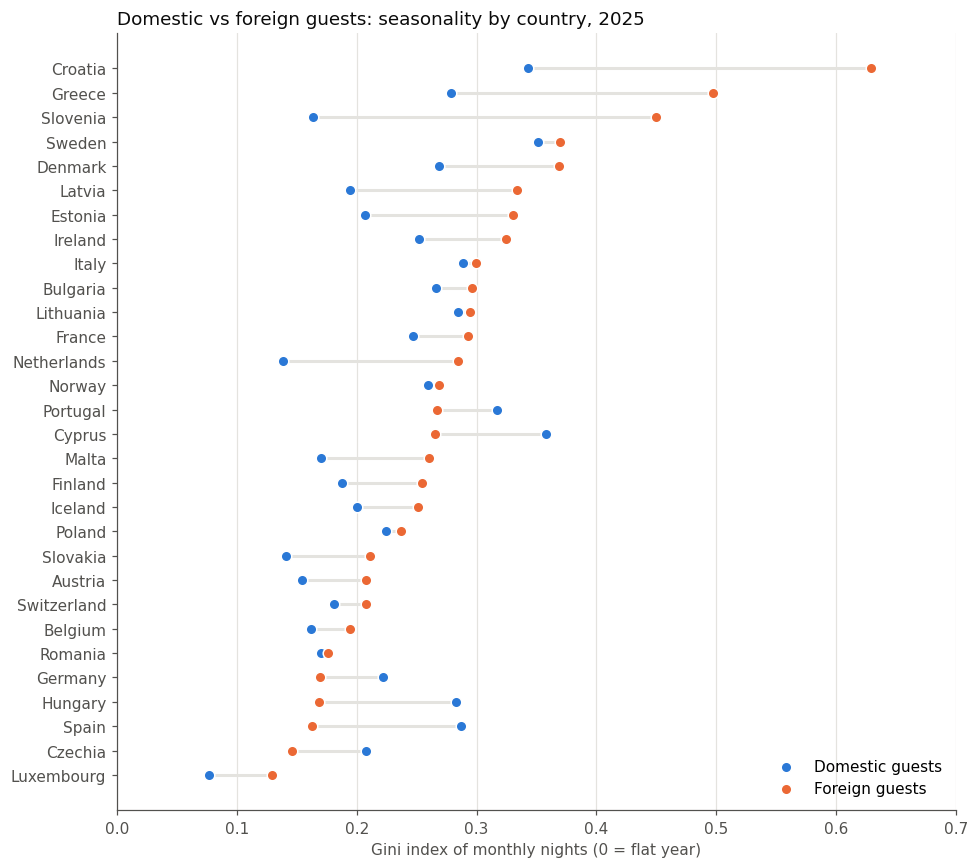

NUTS 2 regions by guest group and pattern, 2025:


SeasonPattern,Strong summer season,Summer season,Summer season + winter shoulder,Winter-based seasons,Mild or no season,All
ResidenceCountry,,,,,,
Domestic,37,89,11,14,105,256
Foreign,58,131,5,18,43,255
Total,49,119,7,19,64,258
All,144,339,23,51,212,769


Same region: domestic pattern (rows) vs foreign pattern (columns):


Foreign,Strong summer season,Summer season,Summer season + winter shoulder,Winter-based seasons,Mild or no season,All
Domestic,,,,,,
Strong summer season,27,10,0,0,0,37
Summer season,25,53,0,7,4,89
Summer season + winter shoulder,3,4,1,2,1,11
Winter-based seasons,0,3,3,8,0,14
Mild or no season,3,60,1,1,38,103
All,58,130,5,18,43,254


same pattern for domestic and foreign guests: 50% of regions (29% expected by chance)


In [9]:
# Own Gini of foreign vs domestic guests in the same region (or country), by year.
fd = df[(df["Month"] == "Total") & df["ResidenceCountry"].isin(["Domestic", "Foreign"]) & ~df["Region"].str.startswith("Extra")]
fd = fd.pivot_table(index=["NUTSLevel", "NUTSCode", "Year"], columns="ResidenceCountry", values="Gini", observed=True).dropna()
more_seasonal = (100 * (fd["Foreign"] > fd["Domestic"]).groupby(level=["NUTSLevel", "Year"]).mean()).unstack("Year").loc[[0, 2]].round(0)
print("Share where foreign guests are more seasonal than domestic guests (own Gini), by year (%):")
display(more_seasonal.rename(index={0: "countries", 2: "NUTS 2 regions"}))
gap25 = (fd["Foreign"] - fd["Domestic"]).xs((2, 2025), level=["NUTSLevel", "Year"])
print(f"NUTS 2, 2025: foreign more seasonal in {(gap25 > 0).mean():.0%} of {len(gap25)} regions, by more than 0.03 "
      f"(beyond normal yearly movement) in {(gap25 > 0.03).mean():.0%}; domestic more seasonal by more than 0.03 in {(gap25 < -0.03).mean():.0%}; "
      f"median gap {gap25.median():+.3f}; paired Wilcoxon test p = {stats.wilcoxon(gap25).pvalue:.1e}")

# Chart: domestic vs foreign Gini by country, 2025.
gc2 = by_cty[["Gini domestic", "Gini foreign"]].dropna().sort_values("Gini foreign")
dumbbell(gc2, "Gini domestic", "Gini foreign",
         [dict(s=48, color=COLOR[r], edgecolor="white", linewidth=1, label=f"{r} guests", zorder=3) for r in ["Domestic", "Foreign"]],
         (0, 0.7), "Gini index of monthly nights (0 = flat year)", "Domestic vs foreign guests: seasonality by country, 2025")
plt.tight_layout(); plt.show()

# Season pattern of domestic vs foreign guests in the same region, 2025.
pr = pd.concat([annual(2, 2025, r) for r in ("Domestic", "Foreign", "Total")])
pr = pr[pr["SeasonPattern"].notna()]
print("NUTS 2 regions by guest group and pattern, 2025:")
display(pd.crosstab(pr["ResidenceCountry"], pr["SeasonPattern"], margins=True))
dvf = pr.pivot_table(index="NUTSCode", columns="ResidenceCountry", values="SeasonPattern", aggfunc="first", observed=True).dropna(subset=["Domestic", "Foreign"])
print("Same region: domestic pattern (rows) vs foreign pattern (columns):")
display(pd.crosstab(dvf["Domestic"], dvf["Foreign"], margins=True))
pd_, pf_ = dvf["Domestic"].value_counts(normalize=True), dvf["Foreign"].value_counts(normalize=True)
print(f"same pattern for domestic and foreign guests: {(dvf['Domestic'] == dvf['Foreign']).mean():.0%} of regions "
      f"({(pd_ * pf_.reindex(pd_.index).fillna(0)).sum():.0%} expected by chance)")

## 3.3 Their timing raises the typical region's Gini by only about 0.015 — but by about 0.06 in mainly-foreign regions

* **Typical effect.** If foreign guests travelled in the same months as domestic guests, the typical (median) NUTS 2 region's Gini would be about 0.015 lower — within normal year-to-year movement. By foreign share: about 0 in mainly-domestic, 0.02 in mixed and 0.06 in mainly-foreign regions (chart, left). For the EU-27 as a whole: 0.261 instead of 0.241. (Comparing the medians before and after, 0.25 vs 0.21, would overstate the typical effect: different regions sit at the median.)
* **How often it matters.** Foreign timing adds more than 0.03 in 41% of regions (68% of mainly-foreign regions) and lowers seasonality by more than 0.03 in 11% (3.4).
* **Largest values.** The largest positive effects are in regions where foreign guests are 84–95% of nights (Kentriki Makedonia, Anatoliki Makedonia, Zahodna Slovenija). There the "domestic pattern" is borrowed from a small group (about 0.2–1 million nights, column *domestic nights*), so read them as "foreign and domestic timing differ strongly", not as precise amounts.
* **Over time** (the same 237 regions every year): outside COVID the median effect is 0.006–0.014 and foreign timing adds more than 0.03 in 38–41% of regions — no trend. In 2020–21 the effect was around zero (median −0.008 in 2020) and foreign timing lowered seasonality in 24–27% of regions, against 11–16% in other years (chart, right).
* This is an accounting statement: it shows how much of the seasonality is *in* foreign demand, not that foreign guests *cause* it. *Why* foreign guests travel at different times than domestic guests cannot be tested with these data, which do not record guests' countries of origin.

254 regions; median change per region (the typical effect): 0.015 Gini points
foreign timing adds > 0.03 in 41% of regions, lowers by > 0.03 in 11%


,regions,median,share_adding_over_003,share_lowering_over_003
ForeignGroup,,,,
Mainly domestic,82,0.000,0.110,0.024
Mixed,95,0.022,0.463,0.158
Mainly foreign,77,0.057,0.675,0.130


EU-27 2025: Gini 0.261; if foreign guests travelled like domestic guests 0.241
Largest effects of foreign timing, both directions (note the small domestic base at the top):


,Region,Country,PrcForeign,domestic nights,Gini,Gini if foreign travelled like domestic,ForeignTimingEffect
0,Kentriki Makedonia,Greece,83.52,1058235,0.455,0.134,0.322
1,"Anatoliki Makedonia, Thraki",Greece,89.18,204823,0.574,0.280,0.294
2,Zahodna Slovenija,Slovenia,95.14,187215,0.444,0.161,0.283
3,Panonska Hrvatska,Croatia,63.40,201677,0.318,0.120,0.199
4,Thessalia,Greece,69.95,493139,0.451,0.262,0.188
5,Vestlandet,Norway,74.90,685300,0.417,0.234,0.183
6,Algarve,Portugal,85.88,1887458,0.386,0.573,-0.188
7,Canarias,Spain,76.50,7231543,0.096,0.250,-0.154
8,Comunitat Valenciana,Spain,65.19,9763769,0.307,0.434,-0.127
9,Provincia Autonoma di Bolzano/Bozen,Italy,80.70,498551,0.216,0.339,-0.123


ForeignTimingEffect by year, the same 237 NUTS 2 regions every year:


Year,2018,2019,2020,2021,2022,2023,2024,2025
median effect,0.013,0.008,-0.008,-0.001,0.014,0.006,0.012,0.014
share adding > 0.03,0.376,0.384,0.190,0.249,0.384,0.388,0.384,0.405
share lowering > 0.03,0.152,0.156,0.266,0.241,0.156,0.148,0.114,0.110


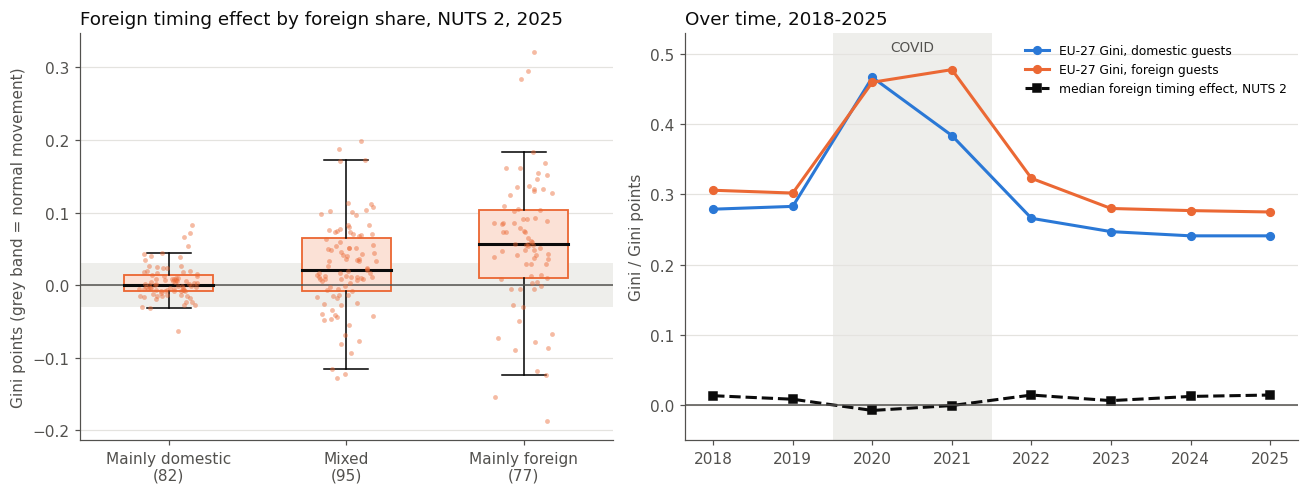

In [10]:
# ForeignTimingEffect (indices notebook, A6b): Gini of all nights minus the Gini if foreign guests kept their number
# of nights but spread them over the year like the region's domestic guests. NUTS 2 regions, 2025.
cf = ok.dropna(subset=["ForeignTimingEffect"]).copy()
cf["domestic nights"] = cf["NUTSCode"].map(annual(2, 2025, "Domestic").set_index("NUTSCode")["Value"])
cf["Gini if foreign travelled like domestic"] = cf["Gini"] - cf["ForeignTimingEffect"]
print(f"{len(cf)} regions; median change per region (the typical effect): {cf['ForeignTimingEffect'].median():.3f} Gini points")
print(f"foreign timing adds > 0.03 in {(cf['ForeignTimingEffect'] > 0.03).mean():.0%} of regions, lowers by > 0.03 in {(cf['ForeignTimingEffect'] < -0.03).mean():.0%}")
by_fg = cf.groupby("ForeignGroup", observed=True)["ForeignTimingEffect"].agg(
    regions="size", median="median", share_adding_over_003=lambda s: (s > 0.03).mean(), share_lowering_over_003=lambda s: (s < -0.03).mean()).round(3)
display(by_fg)

# EU-27 as a whole (monthly sums of all EU countries).
eu_d, eu_f = eu_months(2025, "Domestic"), eu_months(2025, "Foreign")
eu_te = (gini(eu_d + eu_f), gini(eu_d + eu_f.sum() * eu_d / eu_d.sum()))
print(f"EU-27 2025: Gini {eu_te[0]:.3f}; if foreign guests travelled like domestic guests {eu_te[1]:.3f}")

print("Largest effects of foreign timing, both directions (note the small domestic base at the top):")
display(pd.concat([cf.nlargest(6, "ForeignTimingEffect"), cf.nsmallest(6, "ForeignTimingEffect")])[
    ["Region", "Country", "PrcForeign", "domestic nights", "Gini", "Gini if foreign travelled like domestic", "ForeignTimingEffect"]].round(3).reset_index(drop=True))

# Over time: regions with data in every year 2018-2025 (leaves out the Dutch and Portuguese regions that start in 2024).
te_y = annual(2).dropna(subset=["ForeignTimingEffect"]).pivot_table(index="NUTSCode", columns="Year", values="ForeignTimingEffect").dropna()
te_sum = pd.DataFrame({"median effect": te_y.median(), "share adding > 0.03": (te_y > 0.03).mean(), "share lowering > 0.03": (te_y < -0.03).mean()}).round(3)
print(f"ForeignTimingEffect by year, the same {len(te_y)} NUTS 2 regions every year:")
display(te_sum.T)

# Chart: left = the effect by foreign group (2025), right = over time (EU-27 Gini of each guest group, and the regional median effect).
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), dpi=110, gridspec_kw={"width_ratios": [1, 1.15]})
groups_ = [g for g in CATEGORIES["ForeignGroup"] if g in set(cf["ForeignGroup"].astype(str))]
data_ = [cf.loc[cf["ForeignGroup"] == g, "ForeignTimingEffect"] for g in groups_]
ax.axhspan(-0.03, 0.03, color=GRIDC, alpha=0.6, lw=0, zorder=0)
bp = ax.boxplot(data_, widths=0.5, patch_artist=True, showfliers=False, medianprops={"color": INK, "lw": 2})
for patch in bp["boxes"]:
    patch.set(facecolor="#fbe1d6", edgecolor=COLOR["Foreign"], lw=1.2)
rng_j = np.random.default_rng(3)
for i, d in enumerate(data_, start=1):
    ax.scatter(i + rng_j.uniform(-0.17, 0.17, len(d)), d, s=10, color=COLOR["Foreign"], alpha=0.45, lw=0, zorder=3)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(range(1, len(groups_) + 1), [f"{g}\n({len(d)})" for g, d in zip(groups_, data_)])
style(ax, "Foreign timing effect by foreign share, NUTS 2, 2025", "Gini points (grey band = normal movement)")
yrs_ = list(range(2018, 2026))
for r in ["Domestic", "Foreign"]:
    ax2.plot(yrs_, [eu_g[r][y] for y in yrs_], color=COLOR[r], lw=2, marker="o", ms=5, label=f"EU-27 Gini, {r.lower()} guests")
ax2.plot(yrs_, te_sum["median effect"].reindex(yrs_), color=INK, lw=2, ls="--", marker="s", ms=5, label="median foreign timing effect, NUTS 2")
ax2.axvspan(2019.5, 2021.5, color=GRIDC, alpha=0.6, lw=0); ax2.text(2020.5, 0.505, "COVID", ha="center", color=MUTED, fontsize=9)
ax2.axhline(0, color=MUTED, lw=1)
ax2.set_xticks(yrs_); ax2.set_ylim(-0.05, 0.53)
style(ax2, "Over time, 2018-2025", "Gini / Gini points")
ax2.legend(frameon=False, loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

## 3.4 Where domestic guests make a sharp August peak, foreign guests lower seasonality

**Which group has the sharper summer peak decides the direction.** For each region, the July–August peak of each guest group is measured as its July–August nights per average month, and the regions are grouped by how far apart the two peaks are ("much sharper" = more than 0.25 apart; first table below). Effect of foreign timing on the region's Gini (more than ±0.03 = beyond normal movement):

| July–August peak | Lowers seasonality | No clear effect | Raises seasonality | Regions |
|---|---|---|---|---|
| domestic peak much sharper | **49%** | 43% | 8% | 37 |
| foreign peak much sharper | 2% | 30% | **67%** | 125 |

Where domestic guests crowd into the summer more than foreign guests, foreign guests mostly lower seasonality, or make no clear difference; they almost never raise it. Where foreign guests crowd in more, it is the reverse. In between (peaks less than 0.25 apart; 92 regions) the effect is mostly too small to tell from zero.


* The largest such regions are Spain's and southern Italy's coasts and islands — Andalucía, Canarias, Comunitat Valenciana, Sicilia, Puglia, Sardegna — and the Algarve: foreign guests fill the shoulder months (and in Canarias the winter) that domestic guests leave empty. This holds even in mainly-foreign regions (10 of 77).
* Nationally the same holds in Hungary, Cyprus, Spain, Czechia and Portugal — countries where domestic guests are the more seasonal group (3.2). In Germany domestic guests are also more seasonal, but with 29% foreign nights the effect stays small (−0.017).

In [11]:
# Where does foreign timing lower seasonality? Compare the height of the July-August peak of the two guest groups.
peak = (wide[["July", "August"]].mean(axis=1) / wide.mean(axis=1)).unstack("ResidenceCountry")
gap_ = (peak["Domestic"] - peak["Foreign"]).xs(2025, level="Year").reindex(cf["NUTSCode"]).to_numpy()
cf["peak_gap"] = pd.cut(gap_, [-np.inf, -0.25, 0, 0.25, np.inf],
                        labels=["foreign peak much sharper", "foreign a bit sharper", "domestic a bit sharper", "domestic peak much sharper"])
print("Foreign timing class by which guest group has the sharper July-August peak (% of regions):")
display((100 * pd.crosstab(cf["peak_gap"], cf["ForeignTimingClass"], normalize="index")).round(0).assign(regions=cf["peak_gap"].value_counts()))

print("Largest regions where foreign timing lowers seasonality (> 0.03):")
display(cf[cf["ForeignTimingClass"] == "Reduces"].nlargest(10, "Value")[["Region", "Country", "PrcForeign", "Gini", "ForeignTimingEffect"]].reset_index(drop=True))
print(f"mainly-foreign regions where foreign timing lowers seasonality: {((cf['ForeignGroup'] == 'Mainly foreign') & (cf['ForeignTimingClass'] == 'Reduces')).sum()} "
      f"of {(cf['ForeignGroup'] == 'Mainly foreign').sum()}")

# Countries: the same effect at national level.
ct_te = cty.set_index("Country")[["PrcForeign", "Gini", "ForeignTimingEffect", "ForeignTimingClass"]].dropna(subset=["ForeignTimingEffect"])
ct_te = ct_te.join(by_cty[["Gini domestic", "Gini foreign"]]).sort_values("ForeignTimingEffect")
print("Countries, 2025, by foreign timing effect:")
display(ct_te.round(3))

Foreign timing class by which guest group has the sharper July-August peak (% of regions):


ForeignTimingClass,Reduces,No clear effect,Adds,regions
peak_gap,,,,
foreign peak much sharper,2.0,30.0,67.0,125
foreign a bit sharper,2.0,74.0,25.0,61
domestic a bit sharper,16.0,74.0,10.0,31
domestic peak much sharper,49.0,43.0,8.0,37


Largest regions where foreign timing lowers seasonality (> 0.03):


,Region,Country,PrcForeign,Gini,ForeignTimingEffect
0,Andalucía,Spain,62.46,0.2139,-0.0684
1,Canarias,Spain,76.50,0.0955,-0.1541
2,Comunitat Valenciana,Spain,65.19,0.3067,-0.1272
3,Algarve,Portugal,85.88,0.3858,-0.1875
4,Sicilia,Italy,73.84,0.3577,-0.1177
5,Notio Aigaio,Greece,91.17,0.5781,-0.0779
6,Puglia,Italy,66.88,0.4615,-0.1224
7,Sardegna,Italy,70.79,0.5548,-0.0724
8,Kýpros,Cyprus,90.83,0.2714,-0.0866
9,Região Autónoma da Madeira,Portugal,92.20,0.1503,-0.0495


mainly-foreign regions where foreign timing lowers seasonality: 10 of 77
Countries, 2025, by foreign timing effect:


,PrcForeign,Gini,ForeignTimingEffect,ForeignTimingClass,Gini domestic,Gini foreign
Country,,,,,,
Hungary,85.15,0.183,-0.100,Reduces,0.283,0.168
Cyprus,90.83,0.271,-0.087,Reduces,0.358,0.265
Spain,64.39,0.205,-0.082,Reduces,0.287,0.163
Czechia,71.60,0.158,-0.050,Reduces,0.207,0.146
Portugal,85.84,0.272,-0.045,Reduces,0.317,0.267
Finland,51.19,0.171,-0.017,No clear effect,0.188,0.255
Germany,28.97,0.205,-0.017,No clear effect,0.222,0.170
Switzerland,71.95,0.169,-0.012,No clear effect,0.181,0.207
Norway,70.37,0.253,-0.006,No clear effect,0.259,0.269


# 4. What explains seasonality?

## 4.1 Geography explains the season's shape

* Three links between season pattern and geography are **strong**: significant after correcting for testing 60 combinations and the same in 2023, 2024 and 2025; the first two also hold clearly when patterns are compared only within countries, the third does not (tables at the end):
  * **Predominantly urban ↔ Mild or no season** (both ways): 45 of the 64 mild-or-no-season regions are urban, twice the number expected, and half of all urban regions have mild or no season.
  * **Coast → Strong summer season** (one way): 45 of 49 strong-summer regions are at least partly coastal, but only about 4 in 10 coastal regions have a strong summer season — a coast is needed, not sufficient. For *predominantly* coastal regions the link is mostly a difference between countries: comparing regions only within their own country, about 21 of the 25 would be expected anyway (table: *expected within countries*), because the countries with many coastal regions are strong-summer countries throughout — above all Greece, with 8 of the 25 (11 of its 13 regions have a strong summer season, coastal or not).
  * **Inland mountain → Winter-based seasons** (one way): 11 of the 19 winter-based regions are predominantly inland mountain (3.8 × expected), but most mountain regions still have a summer season. Within countries the link is weaker (11 regions against about 6 expected) and not significant after the correction for 60 tests. Much of the link is that the Alpine countries have both many mountain regions and many winter-based regions: 6 of the 11 are in Austria and Switzerland. Comparing regions only within their own country, about 6 of the 11 would be expected anyway.
* No strong link for islands (no association with the pattern at all), for rural regions, or for the *Summer season* pattern, which occurs everywhere. *Summer season + winter shoulder* (7 regions, mostly lower mountains such as Bolzano, Trento, Kärnten) is too small to test.
* Seasonality rises from urban to rural and from inland to coast. Across all regions coastal location explains the most (η² ≈ 0.29, against 0.15 for urbanisation); **within countries the two matter equally** (≈ 0.12 each), so part of the coastal effect is a difference between countries (Croatia, Greece). With all four shares together, rurality and coast both add to seasonality, islands add nothing beyond being coastal, and within countries inland mountains slightly *lower* the Gini index (two seasons fill each other's off-season; borderline, p ≈ 0.07). Standard errors allow regions of the same country to be alike (clustered by country). Foreign share is tested on top of geography in 4.2.

In [12]:
for col in ["CoastalGroup", "InlandMountainGroup", "UrbanGroup", "IslandGroup"]:
    display(pd.crosstab(ok[col], ok["SeasonPattern"], margins=True))

print("Share of each group's nights by Gini group (%):")
for col in ["UrbanGroup", "CoastalGroup", "IslandGroup"]:
    display((100 * pd.crosstab(ok[col], ok["GiniMapGroup"], values=ok["Value"], aggfunc="sum", normalize="index")).round(1))

# How much of the variation in Gini between regions each grouping explains (eta squared:
# between-group sum of squares / total sum of squares; 0 = nothing, 1 = everything) - across all regions,
# and within countries (Gini minus the country's average, countries with 3+ regions).
GEO_G = ["CoastalGroup", "UrbanGroup", "IslandGroup", "InlandMountainGroup"]
def eta2(d, col, y="Gini"):
    d = d.dropna(subset=[col, y]); gm = d[y].mean()
    t = d.groupby(col, observed=True)[y].agg(["mean", "size"])
    return (t["size"] * (t["mean"] - gm) ** 2).sum() / ((d[y] - gm) ** 2).sum()
w3 = w_.assign(Gw=w_["Gini"] - w_.groupby("c_")["Gini"].transform("mean"))   # w_: countries with 3+ regions (3.1)
print("Share of the variation in Gini explained by each grouping (NUTS 2, 2025):")
display(pd.DataFrame({"all regions": {c: round(eta2(ok, c), 3) for c in GEO_G},
                      "within countries": {c: round(eta2(w3, c, "Gw"), 3) for c in GEO_G}}))

# All four shares together: linear regression of Gini on the shares (0-1), without and with country effects
# (one dummy per country, so only differences within countries count). Coefficient = change in Gini from 0% to 100%.
# Regions of one country are not independent, so the standard errors are clustered by country.
def ols_cluster(y, X, groups):
    """OLS coefficients with country-clustered standard errors (CR1, as in Stata / statsmodels)
    and p-values from a t distribution with (number of countries - 1) degrees of freedom."""
    y, X = np.asarray(y, float), np.asarray(X, float)
    XtX_inv = np.linalg.inv(X.T @ X); b = XtX_inv @ X.T @ y; u = y - X @ b
    g_codes = pd.factorize(np.asarray(groups))[0]; G = g_codes.max() + 1; n, k = X.shape
    meat = sum(np.outer(X[g_codes == g].T @ u[g_codes == g], X[g_codes == g].T @ u[g_codes == g]) for g in range(G))
    se = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv) * G / (G - 1) * (n - 1) / (n - k))
    p = 2 * stats.t.sf(np.abs(b / se), G - 1)
    r2 = 1 - (u @ u) / ((y - y.mean()) ** 2).sum()
    return b, se, p, r2

GEO_SHARES = ["PrcCoastal", "PrcRural", "PrcIsland", "PrcInlandMountain"]
gs = ok.dropna(subset=GEO_SHARES + ["PrcForeign"])
Zs = gs[GEO_SHARES].to_numpy() / 100
gcty = gs["Country"].astype(str)
cty_dummies = pd.get_dummies(gcty, drop_first=True, dtype=float).to_numpy()
reg = {}
for name, extra in [("shares only", []), ("shares + country", [cty_dummies])]:
    Xr = np.column_stack([np.ones(len(gs)), Zs] + extra)
    b_, se_, p_, r2_ = ols_cluster(gs["Gini"], Xr, gcty)
    reg[name] = {**{k: f"{b_[j + 1]:+.3f} ± {se_[j + 1]:.3f} (p {p_[j + 1]:.3f})"
                    for j, k in enumerate(["coastal", "rural", "island", "inland mountain"])}, "R²": round(r2_, 2)}
print("Regression of Gini on the geography shares (coefficient ± clustered standard error):")
display(pd.DataFrame(reg))

# Which pattern-geography links are strong? Chi-squared association (Cramér's V) with permutation p-values:
# 'free' shuffles the patterns across all regions; 'within country' shuffles them only inside each country, so a link
# that is just a difference between countries (Croatia, Greece) does not count.
rng = np.random.default_rng(42); NPERM = 5000
def chi2_(ct):
    E = np.outer(ct.sum(1), ct.sum(0)) / ct.sum(); m = E > 0
    return ((ct - E) ** 2 / np.where(m, E, 1))[m].sum()
def tab(gc, pc, ng):
    t = np.zeros((ng, len(PATTERNS))); np.add.at(t, (gc, pc), 1); return t
assoc, cells_ = {}, []
for col in GEO_G:
    s_ = ok.dropna(subset=[col, "SeasonPattern"])
    levels = [l for l in s_[col].cat.categories if (s_[col] == l).any()]
    gc, pc = pd.Categorical(s_[col], categories=levels).codes, pd.Categorical(s_["SeasonPattern"], categories=PATTERNS).codes
    ct = tab(gc, pc, len(levels)); X2 = chi2_(ct)
    cty_ = s_["Country"].astype(str).to_numpy(); groups = [np.flatnonzero(cty_ == c_) for c_ in np.unique(cty_)]
    free, within, n_free, n_within = [], [], [], []
    for _ in range(NPERM):
        t1 = tab(gc, rng.permutation(pc), len(levels)); free.append(chi2_(t1)); n_free.append(t1)
        p2 = pc.copy()
        for ix in groups:
            p2[ix] = rng.permutation(pc[ix])
        t2 = tab(gc, p2, len(levels)); within.append(chi2_(t2)); n_within.append(t2)
    n_free, n_within = np.array(n_free), np.array(n_within)
    assoc[col] = {"Cramér's V": round(np.sqrt(X2 / (ct.sum() * (min(len(levels), (ct.sum(0) > 0).sum()) - 1))), 2),
                  "p (free)": round((np.sum(np.array(free) >= X2) + 1) / (NPERM + 1), 4),
                  "p (within country)": round((np.sum(np.array(within) >= X2) + 1) / (NPERM + 1), 4)}
    E = np.outer(ct.sum(1), ct.sum(0)) / ct.sum()
    for i_, lv in enumerate(levels):
        for j_, p_ in enumerate(PATTERNS):
            if E[i_, j_] == 0:
                continue
            cells_.append({"geography": lv, "pattern": p_, "regions": int(ct[i_, j_]), "expected": round(E[i_, j_], 1),
                           "expected within countries": round(n_within[:, i_, j_].mean(), 1), "lift": round(ct[i_, j_] / E[i_, j_], 2),
                           "% of pattern": round(100 * ct[i_, j_] / ct[:, j_].sum()), "% of geography group": round(100 * ct[i_, j_] / ct[i_].sum()),
                           "p_free": (np.sum(n_free[:, i_, j_] >= ct[i_, j_]) + 1) / (NPERM + 1),
                           "p_within": (np.sum(n_within[:, i_, j_] >= ct[i_, j_]) + 1) / (NPERM + 1)})
print("Association of SeasonPattern with each geography grouping (NUTS 2, 2025):")
display(pd.DataFrame(assoc).T)
links = pd.DataFrame(cells_); m_ = len(links)
links["also within countries"] = links["p_within"] * m_ < 0.05
print("The strong links by year (regions observed / expected):")
for col, lv, p_ in [("UrbanGroup", "Predominantly urban", "Mild or no season"),
                    ("InlandMountainGroup", "Predominantly inland mountain", "Winter-based seasons"),
                    ("CoastalGroup", "Partly coastal", "Strong summer season")]:
    out = []
    for y in (2023, 2024, 2025):
        a_ = annual(2, y); a_ = a_[a_["VolumeOK"] == 1].dropna(subset=[col, "SeasonPattern"])
        o_ = ((a_[col] == lv) & (a_["SeasonPattern"] == p_)).sum(); x_ = (a_[col] == lv).sum() * (a_["SeasonPattern"] == p_).sum() / len(a_)
        out.append(f"{y}: {o_} / {x_:.1f}")
    print(f"  {lv} x {p_}: " + " | ".join(out))
print(f"Pattern-geography links more frequent than expected, significant after Bonferroni over {m_} cells:")
links[(links["p_free"] * m_ < 0.05) & (links["lift"] > 1)].sort_values("lift", ascending=False).drop(columns=["p_free", "p_within"])

SeasonPattern,Strong summer season,Summer season,Summer season + winter shoulder,Winter-based seasons,Mild or no season,All
CoastalGroup,,,,,,
Non-coastal,4,67,7,12,50,140
Partly coastal,20,25,0,2,4,51
Predominantly coastal,25,27,0,5,10,67
All,49,119,7,19,64,258


SeasonPattern,Strong summer season,Summer season,Summer season + winter shoulder,Winter-based seasons,Mild or no season,All
InlandMountainGroup,,,,,,
Non-inland mountain,39,76,0,5,42,162
Partly inland mountain,8,24,3,3,18,56
Predominantly inland mountain,2,18,4,11,4,39
All,49,118,7,19,64,257


SeasonPattern,Strong summer season,Summer season,Summer season + winter shoulder,Winter-based seasons,Mild or no season,All
UrbanGroup,,,,,,
Predominantly urban,6,33,0,4,45,88
Intermediate,31,68,5,14,18,136
Predominantly rural,12,18,2,1,1,34
All,49,119,7,19,64,258


SeasonPattern,Strong summer season,Summer season,Summer season + winter shoulder,Winter-based seasons,Mild or no season,All
IslandGroup,,,,,,
Non-island,41,109,7,17,60,234
Partly island,1,1,0,0,0,2
Predominantly island,7,8,0,2,4,21
All,49,118,7,19,64,257


Share of each group's nights by Gini group (%):


GiniMapGroup,Low,Medium,High
UrbanGroup,,,
Predominantly urban,38.4,32.7,28.9
Intermediate,17.0,30.7,52.3
Predominantly rural,3.6,18.6,77.8


... (6 outputs left out)

Association of SeasonPattern with each geography grouping (NUTS 2, 2025):


,Cramér's V,p (free),p (within country)
CoastalGroup,0.35,0.0002,0.0002
UrbanGroup,0.34,0.0002,0.0002
IslandGroup,0.10,0.5871,0.8998
InlandMountainGroup,0.32,0.0002,0.0002


The strong links by year (regions observed / expected):
  Predominantly urban x Mild or no season: 2023: 41 / 21.1 | 2024: 43 / 20.5 | 2025: 45 / 21.8
  Predominantly inland mountain x Winter-based seasons: 2023: 11 / 2.5 | 2024: 12 / 2.9 | 2025: 11 / 2.9
  Partly coastal x Strong summer season: 2023: 20 / 9.1 | 2024: 19 / 9.7 | 2025: 20 / 9.7
Pattern-geography links more frequent than expected, significant after Bonferroni over 60 cells:


,geography,pattern,regions,expected,expected within countries,lift,% of pattern,% of geography group,also within countries
58,Predominantly inland mountain,Winter-based seasons,11,2.9,6.1,3.82,58,28,False
5,Partly coastal,Strong summer season,20,9.7,11.8,2.06,41,39,True
19,Predominantly urban,Mild or no season,45,21.8,26.0,2.06,70,51,True
10,Predominantly coastal,Strong summer season,25,12.7,20.9,1.96,51,37,False
4,Non-coastal,Mild or no season,50,34.7,45.3,1.44,78,36,False


## 4.2 Foreign share adds nothing once geography and country are known

3.1 shows that foreign share and seasonality are only loosely related; 4.1 that geography matters. Are foreign guests a separate factor, or do they simply go where the seasonal places are? Regression (chart: effects with 95% intervals) of each NUTS 2 region's Gini index (2025) on its foreign share, step by step adding the four geography shares and country effects (standard errors clustered by country):

| Model | Foreign share, 0 → 100% (change in Gini) | p | R² |
|---|---|---|---|
| Foreign share only | +0.09 | 0.16 | 0.03 |
| + geography | +0.10 | 0.008 | 0.42 |
| + geography + country | +0.04 | 0.58 | 0.55 |
| same, weighted by nights | −0.06 | 0.39 | |

* On its own, foreign share explains 3% of the differences in seasonality between regions.
* With geography it looks significant — but only because it then picks up **differences between countries**: Croatia and Greece are both very foreign and very seasonal. Within countries (country effects added) it adds nothing (R² 0.544 → 0.546), and among the large regions (weighted by nights) the sign even turns negative.
* Geography holds in every model: from 0% to 100% coastal adds about 0.14–0.18 to the Gini index, from 0% to 100% rural about 0.33–0.36 (the largest single factor); islands add nothing beyond being coastal; inland mountains lower it slightly within countries (two seasons).

This answers *"are there influential factors?"* for the data at hand: **where** a region is (coast, countryside, country) shapes its seasonality; **who** its guests are does not add anything once that is known. Foreign guests matter for *when* the season is (3.2: they are more summer-concentrated than domestic guests in about three-quarters of regions), not for *which regions* are seasonal. Not in the data, and so not tested: guests' countries of origin, climate, airport access, ski infrastructure and accommodation supply.

,foreign share (0→100%),R²,coastal,rural,island,inland mountain
foreign share only,+0.087 ± 0.060 (p 0.160),0.028,,,,
+ geography,+0.104 ± 0.037 (p 0.008),0.418,+0.162 ± 0.032,+0.356 ± 0.048,-0.027 ± 0.035,-0.016 ± 0.021
+ geography + country,+0.044 ± 0.079 (p 0.578),0.546,+0.142 ± 0.038,+0.353 ± 0.061,-0.005 ± 0.039,-0.052 ± 0.027
geography + country (no foreign),—,0.544,+0.143 ± 0.038,+0.333 ± 0.040,-0.002 ± 0.040,-0.052 ± 0.028


weighted by nights, + geography + country: foreign share -0.064 ± 0.074 (p 0.39)


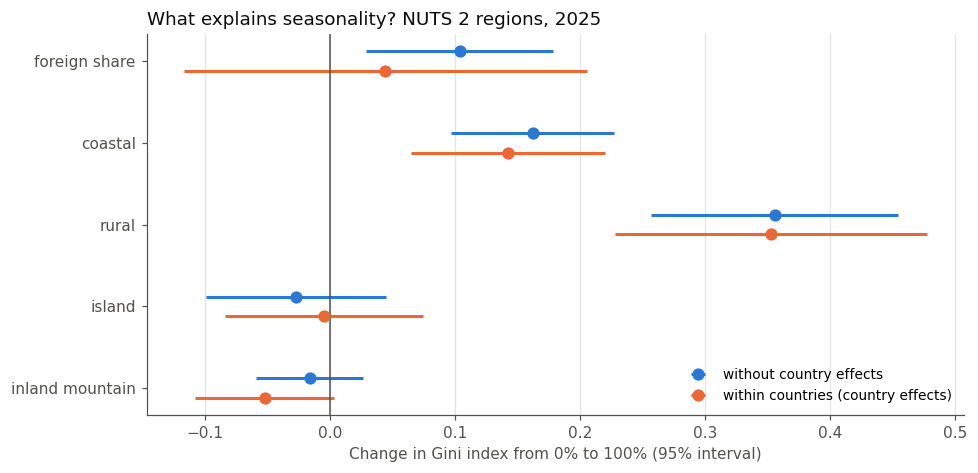

In [13]:
# Gini ~ foreign share (+ geography shares) (+ country effects), NUTS 2 regions 2025, clustered by country.
F = gs[["PrcForeign"]].to_numpy() / 100
models = {"foreign share only":              [F],
          "+ geography":                      [F, Zs],
          "+ geography + country":            [F, Zs, cty_dummies],
          "geography + country (no foreign)": [Zs, cty_dummies]}
rows, FIT = {}, {}
for name, parts in models.items():
    Xr = np.column_stack([np.ones(len(gs))] + parts)
    b_, se_, p_, r2_ = ols_cluster(gs["Gini"], Xr, gcty)
    FIT[name] = (b_, se_, p_, r2_)
    has_f = parts[0] is F                                      # is foreign share in this model?
    row = {"foreign share": f"{b_[1]:+.3f} ± {se_[1]:.3f} (p {p_[1]:.3f})" if has_f else "—"}
    off = 1 if has_f else 0                                    # column offset of the geography shares
    if any(part is Zs for part in parts):
        row |= {k: f"{b_[1 + off + j]:+.3f} ± {se_[1 + off + j]:.3f}" for j, k in enumerate(["coastal", "rural", "island", "inland mountain"])}
    rows[name] = row | {"R²": round(r2_, 3)}
display(pd.DataFrame(rows).T.fillna("").rename(columns={"foreign share": "foreign share (0→100%)"}))

# Weighted by nights: do the large tourism regions tell a different story?
Xw = np.column_stack([np.ones(len(gs)), F, Zs, cty_dummies]); sw = np.sqrt(gs["Value"].to_numpy(float))
b_, se_, p_, _ = ols_cluster(gs["Gini"].to_numpy() * sw, Xw * sw[:, None], gcty)
print(f"weighted by nights, + geography + country: foreign share {b_[1]:+.3f} ± {se_[1]:.3f} (p {p_[1]:.2f})")


# Chart: effect of foreign share and of the geography shares (0 -> 100%), with 95% intervals, with and without country effects.
labels_ = ["foreign share", "coastal", "rural", "island", "inland mountain"]
fig, ax = plt.subplots(figsize=(9, 4.4), dpi=110)
for k, (name, col_, off) in enumerate([("+ geography", COLOR["Domestic"], -0.12), ("+ geography + country", COLOR["Foreign"], 0.12)]):
    b_, se_, p_, _ = FIT[name]; G_ = gcty.nunique()
    ci = stats.t.ppf(0.975, G_ - 1) * se_[1:6]
    ax.errorbar(b_[1:6], np.arange(5) + off, xerr=ci, fmt="o", ms=7, color=col_, ecolor=col_, elinewidth=2, capsize=0,
                label="without country effects" if k == 0 else "within countries (country effects)")
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(np.arange(5), labels_); ax.invert_yaxis()
ax.set_xlabel("Change in Gini index from 0% to 100% (95% interval)", color=MUTED)
style(ax, "What explains seasonality? NUTS 2 regions, 2025")
ax.grid(axis="x", color=GRIDC, lw=0.8); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right", fontsize=9); plt.tight_layout(); plt.show()

# Conclusions

1. **Foreign tourism** is the majority of platform-booked nights almost everywhere (62% EU-wide) but concentrated: mainly-foreign regions hold two-thirds of all foreign nights, the ten largest regions over a third. Its share is slowly falling as domestic platform stays grow faster.
2. **Seasonality** is one summer season centred on July–August in most of Europe, somewhat less concentrated since 2023. Cities have little season; ski regions have two.
3. **Foreign guests** travel in a more summer-heavy way than domestic guests in about three-quarters of regions, but this only noticeably raises a region's seasonality where they are a large share of the guests. Where domestic guests crowd into August, foreign guests even smooth the year.
4. **What makes a region seasonal** is where it is — coast, countryside, country — not who its guests are. For a map, the foreign share and the season are two separate dimensions; the regions where both are high (*double exposure*: about 30 regions, a fifth of all nights — the Croatian coast, the Greek islands, Balearics, Algarve, Toscana, Sicilia) are the ones most exposed to a change in foreign demand.

## Limitations

* **Platform bookings only** (Airbnb, Booking, Expedia, Tripadvisor): hotels booked directly and most domestic holiday homes are missing; growth since 2019, and part of the fall in seasonality, partly reflect wider platform use and a changing mix of who books through them.
* **Foreign guests are one group** — the data give no countries of origin, so the role of individual source markets (e.g. Northern Europeans in the shoulder months) cannot be tested.
* **Mostly a 2025 snapshot**; trends are given for 2019–2025 only where they are larger than normal year-to-year movement. Dutch and Portuguese NUTS 2 regions start in 2024.
* **Geography shares describe residents**, not where guests stay; climate, airport access, ski infrastructure, accommodation supply and prices are not in the data.
* Results are associations and accounting comparisons, not causal effects.

# Appendix A — Marginal effect of foreign demand (RMEForeign)

The standard measure in the literature (Fernández-Morales et al. 2016): how much the region's Gini index would change, relatively, if foreign demand grew a little with its current monthly pattern (indices notebook, A6). Classes: *Smoothing* ≤ −0.02, *Sharpening* ≥ 0.02.

* It agrees with ForeignTimingEffect (rank correlation 0.80 across NUTS 2 regions) and gives the same picture: *sharpening* in 62% of regions in 2025, *smoothing* in 18%; only 4 of 78 mainly-foreign regions are *smoothing*.
* **Near 100% foreign it is pulled towards 0**: there foreign guests almost *are* the total, so the measure cannot be large in either direction (table (a)) — one reason ForeignTimingEffect is the main measure here.
* **The marginal effect is small:** 10% more foreign nights would raise a typical sharpening region's Gini by about 0.002, and move fewer than 1% of regions by more than 0.01 (b). Growth in foreign demand pushes seasonality slowly; it is not a big lever.
* **Relative vs absolute:** RMEForeign is relative to the region's Gini. In cities with almost no season it can look large while changing little — Madrid's RME (0.26) is among the highest, but its Gini is only 0.055. *AbsEffect = RMEForeign × Gini* puts it in Gini points: ≈ 0.014 for Madrid. The largest absolute effects are where foreign guests come in a season domestic guests don't share — Pohjois- ja Itä-Suomi (Lapland's winter), northern Greece, continental Croatia.
* **"Foreign guests are more seasonal" (their own Gini is higher) is not the same as "foreign guests add to seasonality"** (the effect class): the effect also depends on their share of nights and on whether they peak in the same months as everyone else. Every *sharpening* country is in the "foreign more seasonal" group; the rest of that group is *small or unclear*.
* In the COVID years the share of regions where foreign guests smoothed the year rose from about 20% (2019) to 35% (2020).

In [14]:
# RMEForeign (indices notebook, A6): relative marginal effect of foreign demand on the Gini index (Fernández-Morales et al. 2016).
# AbsEffect = RMEForeign x Gini: the same in Gini points (per 100% growth of foreign nights in every month).
e = ann[ann["ForeignSeasonEffect"].notna()].assign(AbsEffect=lambda x: (x["RMEForeign"] * x["Gini"]).round(4))
print("NUTS 2 regions, 2025 - RMEForeign class by foreign group:")
display(pd.crosstab(e["ForeignGroup"], e["ForeignSeasonEffect"], margins=True))
print("Share of NUTS 2 regions in each class, by year (%):")
yrs = pd.concat([annual(2, y) for y in range(2018, 2026)])
display((100 * pd.crosstab(yrs["Year"], yrs["ForeignSeasonEffect"], normalize="index")).round(1))
cols = ["Region", "Country", "Value", "PrcForeign", "RMEForeign", "Gini", "AbsEffect"]
print("Highest relative effect (RMEForeign) - note Madrid: high RME, tiny Gini:")
display(e.nlargest(6, "RMEForeign")[cols].reset_index(drop=True))
print("Highest absolute effect (AbsEffect):")
display(e.nlargest(6, "AbsEffect")[cols].reset_index(drop=True))

# (a) Near 100% foreign, foreign guests almost are the total, so RMEForeign is pulled towards 0.
e2 = e.assign(band=pd.cut(e["PrcForeign"], [0, 20, 40, 55, 70, 85, 100], include_lowest=True))
print("(a) RMEForeign by foreign share, NUTS 2 regions 2025:")
display(e2.groupby("band", observed=True).agg(
    regions=("RMEForeign", "size"), median_RME=("RMEForeign", "median"),
    pct_smoothing=("ForeignSeasonEffect", lambda s: 100 * (s == "Smoothing").mean()),
    pct_sharpening=("ForeignSeasonEffect", lambda s: 100 * (s == "Sharpening").mean())).round({"median_RME": 3, "pct_smoothing": 0, "pct_sharpening": 0}))
# (b) Size of a realistic change: Gini change if foreign nights grew by 10% in every month (= 0.1 x AbsEffect).
print(f"(b) Gini change for +10% foreign nights: median {0.1 * e.loc[e['ForeignSeasonEffect'] == 'Sharpening', 'AbsEffect'].median():+.4f} "
      f"in sharpening regions; {(0.1 * e['AbsEffect'].abs() > 0.01).mean():.1%} of regions would move by more than 0.01")

# Countries: who is more seasonal (own Gini) x RMEForeign class.
cmp_ = by_cty.dropna(subset=["Gini foreign", "Gini domestic", "foreign effect"]).copy()
cmp_["more seasonal"] = np.where(cmp_["Gini foreign"] > cmp_["Gini domestic"], "Foreign guests", "Domestic guests")
print("Countries: who is more seasonal (rows) x RMEForeign class (columns):")
display(pd.crosstab(cmp_["more seasonal"], cmp_["foreign effect"], margins=True))
display(cmp_.reset_index().groupby(["more seasonal", "foreign effect"], observed=True)["Country"]
        .agg(lambda s: ", ".join(map(str, s))).to_frame("countries"))
# Does RMEForeign agree with ForeignTimingEffect?
both_ = e.dropna(subset=["ForeignTimingEffect"])
print(f"rank correlation RMEForeign ~ ForeignTimingEffect, NUTS 2 2025: {both_['RMEForeign'].corr(both_['ForeignTimingEffect'], method='spearman'):.2f}")

NUTS 2 regions, 2025 - RMEForeign class by foreign group:


ForeignSeasonEffect,Smoothing,Small or unclear,Sharpening,All
ForeignGroup,,,,
Mainly domestic,24,23,37,84
Mixed,18,13,65,96
Mainly foreign,4,17,57,78
All,46,53,159,258


Share of NUTS 2 regions in each class, by year (%):


ForeignSeasonEffect,Smoothing,Small or unclear,Sharpening
Year,,,
2018,16.7,21.1,62.2
2019,20.3,22.7,57.0
2020,34.5,29.3,36.1
2021,32.0,24.8,43.2
2022,20.0,20.8,59.2
2023,22.0,26.0,52.0
2024,17.8,22.9,59.3
2025,17.8,20.5,61.6


Highest relative effect (RMEForeign) - note Madrid: high RME, tiny Gini:


,Region,Country,Value,PrcForeign,RMEForeign,Gini,AbsEffect
0,Pohjois- ja Itä-Suomi,Finland,3057728,56.61,0.3718,0.2833,0.1053
1,Piemonte,Italy,4862082,63.85,0.3238,0.1997,0.0647
2,Panonska Hrvatska,Croatia,551007,63.40,0.2930,0.3183,0.0933
3,Grad Zagreb,Croatia,1534339,76.61,0.2855,0.1508,0.0431
4,Comunidad de Madrid,Spain,13151692,71.69,0.2603,0.0549,0.0143
5,Sjeverna Hrvatska,Croatia,366849,68.91,0.2199,0.3083,0.0678


... (4 outputs left out)

(b) Gini change for +10% foreign nights: median +0.0020 in sharpening regions; 0.4% of regions would move by more than 0.01
Countries: who is more seasonal (rows) x RMEForeign class (columns):


foreign effect,Smoothing,Small or unclear,Sharpening,All
more seasonal,,,,
Domestic guests,4,2,0,6
Foreign guests,0,7,17,24
All,4,9,17,30


countries
more seasonal   foreign effect                                                     
Domestic guests Smoothing                          Germany, Spain, Hungary, Czechia
                Small or unclear                                   Portugal, Cyprus
Foreign guests  Small or unclear  Sweden, Italy, Lithuania, Malta, Iceland, Pola...
                Sharpening        Croatia, Greece, Slovenia, Denmark, Ireland, L...

rank correlation RMEForeign ~ ForeignTimingEffect, NUTS 2 2025: 0.80


# Appendix B — Numbers check

Every number quoted in the text above is hand-written. This cell recomputes them; if the data are updated and a number moves beyond its rounding, the cell fails and lists the statements to update.

In [15]:
# (statement in the text, value computed above, value written in the text, tolerance = half of the last digit written)
peak_tab = 100 * pd.crosstab(cf["peak_gap"], cf["ForeignTimingClass"], normalize="index")
CLAIMS = [
    ("1.1 EU-27 nights 2025, million",                 trend.loc[2025, "Total"],                          952,   0.5),
    ("1.1 EU-27 foreign share 2025, %",                trend.loc[2025, "Foreign share %"],                62,    0.5),
    ("1.1 EU-27 foreign share 2019, %",                trend.loc[2019, "Foreign share %"],                67,    0.5),
    ("1.1 EU-27 foreign share 2020, %",                trend.loc[2020, "Foreign share %"],                42,    0.5),
    ("1.1 domestic nights growth 2019-25, %",          trend.loc[2025, "Domestic, 2019 = 100"] - 100,     112,   0.5),
    ("1.1 foreign nights growth 2019-25, %",           trend.loc[2025, "Foreign, 2019 = 100"] - 100,      73,    0.5),
    ("1.2 Germany foreign share, %",                   fs.loc["Germany", 2025],                          29,    0.5),
    ("1.2 France foreign share, %",                    fs.loc["France", 2025],                           40,    0.5),
    ("1.2 Malta foreign share > 95%",                  float(fs.loc["Malta", 2025] > 95),                1,     0),
    ("1.2 median country foreign share, %",            fs[2025].median(),                                73,    0.5),
    ("1.2 countries where foreign share fell",         (fs["change"] < 0).sum(),                         26,    0),
    ("1.2 ... by more than 5 points",                  (fs["change"] < -5).sum(),                        13,    0),
    ("1.2 mainly-foreign regions",                     (reg_f["ForeignGroup"] == "Mainly foreign").sum(), 78,    0),
    ("1.2 mainly-foreign share of all nights, %",      100 * reg_f.loc[reg_f["ForeignGroup"] == "Mainly foreign", "Value"].sum() / reg_f["Value"].sum(), 48, 0.5),
    ("1.2 mainly-foreign share of foreign nights, %",  100 * reg_f.loc[reg_f["ForeignGroup"] == "Mainly foreign", "foreign_nights"].sum() / reg_f["foreign_nights"].sum(), 64, 0.5),
    ("1.2 top-10 regions' share of foreign nights, %", 100 * top10["foreign_nights"].sum() / reg_f["foreign_nights"].sum(), 36, 0.5),
    ("1.2 regions where foreign share fell, %",        100 * (d_ < 0).mean(),                             74,    0.5),
    ("2.1 one-season regions",                         (ok["SeasonShape"] == "One season").sum(),         199,   0),
    ("2.1 ... centred on July",                        cm.loc["July", "Total"],                           152,   0),
    ("2.1 ... centred on August",                      cm.loc["August", "Total"],                         42,    0),
    ("2.1 domestic August share, %",                   prof.loc["August", "Domestic"],                    18.9,  0.05),
    ("2.1 domestic July share, %",                     prof.loc["July", "Domestic"],                      14.4,  0.05),
    ("2.1 foreign July share, %",                      prof.loc["July", "Foreign"],                       16.5,  0.05),
    ("2.1 foreign August share, %",                    prof.loc["August", "Foreign"],                     16.6,  0.05),
    ("2.1 EU-27 Gini 2019",                            eu_g["Total"][2019],                               0.295, 0.0005),
    ("2.1 EU-27 Gini 2022",                            eu_g["Total"][2022],                               0.298, 0.0005),
    ("2.1 EU-27 Gini 2023",                            eu_g["Total"][2023],                               0.264, 0.0005),
    ("2.1 EU-27 Gini 2025",                            eu_g["Total"][2025],                               0.261, 0.0005),
    ("2.2 two-season regions",                         (ok["SeasonShape"] == "Two seasons").sum(),        15,    0),
    ("2.2 no-clear-season regions",                    (ok["SeasonShape"] == "No clear season").sum(),    44,    0),
    ("2.2 strong summer season regions",               (ok["SeasonPattern"] == "Strong summer season").sum(), 49, 0),
    ("2.2 mild or no season regions",                  (ok["SeasonPattern"] == "Mild or no season").sum(), 64,   0),
    ("2.3 countries where Gini fell 2019-25",           (ch < 0).sum(),                                    18,    0),
    ("3.1 rank correlation, NUTS 2",                   rk(ok),                                           0.14,  0.005),
    ("3.1 rank correlation, countries",                rk(cty),                                          0.19,  0.005),
    ("3.1 within-country rank correlation",            obs_w,                                             -0.19, 0.005),
    ("3.1 double exposure: regions",                   len(dx),                                           30,    0),
    ("3.1 double exposure: % of nights",               100 * dx["Value"].sum() / ok["Value"].sum(),       19.7,  0.05),
    ("3.2 foreign more seasonal, % of regions",        100 * (gap25 > 0).mean(),                          76,    0.5),
    ("3.2 ... by more than 0.03, %",                   100 * (gap25 > 0.03).mean(),                       63,    0.5),
    ("3.2 domestic more seasonal by > 0.03, %",        100 * (gap25 < -0.03).mean(),                      17,    0.5),
    ("3.2 countries 2025: foreign more seasonal, %",   more_seasonal.loc[0, 2025],                        80,    0.5),
    ("3.2 same pattern domestic/foreign, %",           100 * (dvf["Domestic"] == dvf["Foreign"]).mean(),  50,    0.5),
    ("3.3 median timing effect",                       cf["ForeignTimingEffect"].median(),                0.015, 0.0005),
    ("3.3 median, mixed regions",                      by_fg.loc["Mixed", "median"],                      0.02,  0.005),
    ("3.3 median, mainly-foreign regions",             by_fg.loc["Mainly foreign", "median"],             0.06,  0.005),
    ("3.3 adds > 0.03, % of regions",                  100 * (cf["ForeignTimingEffect"] > 0.03).mean(),   41,    0.5),
    ("3.3 adds > 0.03, % of mainly-foreign",           100 * by_fg.loc["Mainly foreign", "share_adding_over_003"], 68, 0.5),
    ("3.3 lowers > 0.03, % of regions",                100 * (cf["ForeignTimingEffect"] < -0.03).mean(),  11,    0.5),
    ("3.3 EU-27 Gini if foreign like domestic",        eu_te[1],                                          0.241, 0.0005),
    ("3.4 lowers where domestic peak much sharper, %", peak_tab.loc["domestic peak much sharper", "Reduces"], 49, 0.5),
    ("3.4 mainly-foreign regions where it lowers",     ((cf["ForeignGroup"] == "Mainly foreign") & (cf["ForeignTimingClass"] == "Reduces")).sum(), 10, 0),
    ("4.2 foreign share, within countries (coef)",     FIT["+ geography + country"][0][1],                0.04,  0.005),
    ("4.2 foreign share, within countries (p)",        FIT["+ geography + country"][2][1],                0.58,  0.005),
    ("4.2 foreign share + geography (p)",              FIT["+ geography"][2][1],                          0.008, 0.0005),
    ("4.2 rural, + geography + country",               FIT["+ geography + country"][0][3],                0.35,  0.005),
    ("4.2 coastal, + geography + country",             FIT["+ geography + country"][0][2],                0.14,  0.005),
    ("1.2 all foreign nights, NUTS 2, million",       tot_f / 1e6,                                       606.8, 0.05),
    ("1.2 top-10 running total, %",                    top10["running total %"].iloc[-1],                 35.9,  0.05),
    ("2.1 foreign June share, %",                      prof.loc["June", "Foreign"],                       10.9,  0.05),
    ("2.1 domestic June share, %",                     prof.loc["June", "Domestic"],                      9.1,   0.05),
    ("2.1 foreign September share, %",                 prof.loc["September", "Foreign"],                  10.0,  0.05),
    ("2.1 domestic September share, %",                prof.loc["September", "Domestic"],                 7.7,   0.05),
    ("2.1 France share change, points",                mix_shift.loc["France", "change (points)"],        2.9,   0.05),
    ("2.1 share change ~ 2019 Gini, correlation",      mix_corr,                                          0.02,  0.005),
    ("2.1 EU Gini, only the mix changes",              mix.loc["Total", "2019 monthly patterns, 2025 country shares (only the mix changes)"], 0.296, 0.0005),
    ("2.1 EU Gini, only the patterns change",          mix.loc["Total", "2025 monthly patterns, 2019 country shares (only the patterns change)"], 0.261, 0.0005),
    ("2.3 Ireland above Italy 2024 and 2025",          float((g_c.loc["Ireland", [2024, 2025]] > g_c.loc["Italy", [2024, 2025]]).all()), 1, 0),
    ("3.1 bootstrap interval, lower",                  boot_ci[0],                                        -0.10, 0.005),
    ("3.1 bootstrap interval, upper",                  boot_ci[1],                                        0.30,  0.005),
    ("3.1 country correlation p",                      p_c,                                               0.31,  0.005),
    ("3.4 domestic much sharper: no clear effect, %",  peak_tab.loc["domestic peak much sharper", "No clear effect"], 43, 0.5),
    ("3.4 domestic much sharper: raises, %",           peak_tab.loc["domestic peak much sharper", "Adds"], 8,   0.5),
    ("3.4 foreign much sharper: raises, %",            peak_tab.loc["foreign peak much sharper", "Adds"], 67,   0.5),
    ("3.4 foreign much sharper: no clear effect, %",   peak_tab.loc["foreign peak much sharper", "No clear effect"], 30, 0.5),
    ("3.4 foreign much sharper: lowers, %",            peak_tab.loc["foreign peak much sharper", "Reduces"], 2,  0.5),
    ("3.4 regions with peaks < 0.25 apart",            cf["peak_gap"].isin(["foreign a bit sharper", "domestic a bit sharper"]).sum(), 92, 0),
    ("4.1 pred. coastal strong summer, expected within countries", links.set_index(["geography", "pattern"]).loc[("Predominantly coastal", "Strong summer season"), "expected within countries"], 21, 0.5),
    ("4.1 ... of which Greek",                         ((ok["CoastalGroup"] == "Predominantly coastal") & (ok["SeasonPattern"] == "Strong summer season") & (ok["Country"] == "Greece")).sum(), 8, 0),
    ("4.1 Greek regions with strong summer season",    ((ok["Country"] == "Greece") & (ok["SeasonPattern"] == "Strong summer season")).sum(), 11, 0),
    ("4.1 mountain winter-based in Austria/Switzerland", ((ok["InlandMountainGroup"] == "Predominantly inland mountain") & (ok["SeasonPattern"] == "Winter-based seasons") & ok["Country"].isin(["Austria", "Switzerland"])).sum(), 6, 0),
    ("4.1 mountain winter-based, expected within countries", links.set_index(["geography", "pattern"]).loc[("Predominantly inland mountain", "Winter-based seasons"), "expected within countries"], 6, 0.5),
    ("A RMEForeign ~ ForeignTimingEffect",             both_["RMEForeign"].corr(both_["ForeignTimingEffect"], method="spearman"), 0.80, 0.005),
]
chk = pd.DataFrame(CLAIMS, columns=["statement", "computed", "in text", "tolerance"])
chk["ok"] = (chk["computed"].astype(float) - chk["in text"]).abs() <= chk["tolerance"] + 1e-9
print(f"{chk['ok'].sum()} of {len(chk)} quoted numbers match the data")
display(chk[~chk["ok"]] if not chk["ok"].all() else chk.round(4))
assert chk["ok"].all(), "numbers quoted in the text no longer match the data - update the statements listed above"

83 of 83 quoted numbers match the data


,statement,computed,in text,tolerance,ok
0,"1.1 EU-27 nights 2025, million",951.6119,952.000,0.5000,True
1,"1.1 EU-27 foreign share 2025, %",62.1792,62.000,0.5000,True
2,"1.1 EU-27 foreign share 2019, %",66.8444,67.000,0.5000,True
3,"1.1 EU-27 foreign share 2020, %",41.7192,42.000,0.5000,True
4,"1.1 domestic nights growth 2019-25, %",112.0395,112.000,0.5000,True
5,"1.1 foreign nights growth 2019-25, %",72.9106,73.000,0.5000,True
6,"1.2 Germany foreign share, %",28.9700,29.000,0.5000,True
7,"1.2 France foreign share, %",39.5700,40.000,0.5000,True
8,1.2 Malta foreign share > 95%,1.0000,1.000,0.0000,True
9,"1.2 median country foreign share, %",73.1500,73.000,0.5000,True
